# PARTIE I - Nettoyage

PARTIE I - Nettoyage

Un notebook du nettoyage des données (non cleané, pour comprendre votre démarche)

démarche : traitement des nan


PARTIE II - EXPLORATION

analyse univariée, multivariée, une réduction dimensionnelle, ainsi que les différentes questions de recherches associées


PARTIE III - CONCLUSION





PARTIE I - Nettoyage

•Sélection des variables

•Gestion des valeurs aberrantes

•Gestion des doublons

•Elimination des non utilisables

•Imputation de valeurs manquantes

In [2]:
!pip install pandas

>Objectif : installation librairies

In [3]:
import numpy as np
import pandas as pd

In [4]:
pd.options.display.max_columns = 50
pd.options.display.max_rows = 100

In [5]:
!pip install missingno

>Objectif : installation des autres librairies pour tableaux et graphiques et importation des fonctions utiles à notre projet

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

In [7]:
import fonctions
from fonctions import *


>Objectif : afficher suffisamment de lignes en output

In [8]:
pd.set_option('display.max_rows', 1000)

>Objectif : importation du csv

In [9]:
nutri_app = pd.read_csv('fr.openfoodfacts.org.products.csv', delimiter='\t')

/Users/laureagrech/opt/anaconda3/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3444: DtypeWarning: Columns (0,3,5,19,20,24,25,26,27,28,35,36,37,38,39,48) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [10]:
nutri_app.head()

,code,url,creator,created_t,created_datetime,last_modified_t,last_modified_datetime,product_name,generic_name,quantity,packaging,packaging_tags,brands,brands_tags,categories,categories_tags,categories_fr,origins,origins_tags,manufacturing_places,manufacturing_places_tags,labels,labels_tags,labels_fr,emb_codes,...,chloride_100g,calcium_100g,phosphorus_100g,iron_100g,magnesium_100g,zinc_100g,copper_100g,manganese_100g,fluoride_100g,selenium_100g,chromium_100g,molybdenum_100g,iodine_100g,caffeine_100g,taurine_100g,ph_100g,fruits-vegetables-nuts_100g,collagen-meat-protein-ratio_100g,cocoa_100g,chlorophyl_100g,carbon-footprint_100g,nutrition-score-fr_100g,nutrition-score-uk_100g,glycemic-index_100g,water-hardness_100g
0,3087,http://world-fr.openfoodfacts.org/produit/0000...,openfoodfacts-contributors,1474103866,2016-09-17T09:17:46Z,1474103893,2016-09-17T09:18:13Z,Farine de blé noir,NaN,1kg,NaN,NaN,Ferme t'y R'nao,ferme-t-y-r-nao,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4530,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489069957,2017-03-09T14:32:37Z,1489069957,2017-03-09T14:32:37Z,Banana Chips Sweetened (Whole),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.000,NaN,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,14.0,NaN,NaN
2,4559,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489069957,2017-03-09T14:32:37Z,1489069957,2017-03-09T14:32:37Z,Peanuts,NaN,NaN,NaN,NaN,Torn & Glasser,torn-glasser,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.071,NaN,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN
3,16087,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489055731,2017-03-09T10:35:31Z,1489055731,2017-03-09T10:35:31Z,Organic Salted Nut Mix,NaN,NaN,NaN,NaN,Grizzlies,grizzlies,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.143,NaN,0.00514,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.0,12.0,NaN,NaN
4,16094,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489055653,2017-03-09T10:34:13Z,1489055653,2017-03-09T10:34:13Z,Organic Polenta,NaN,NaN,NaN,NaN,Bob's Red Mill,bob-s-red-mill,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


>>analyse : aperçu du contenu du fichier et des lignes et colonnes

>Objectif : affichu du contenu/des colonnes du dataset

In [11]:
nutri_app[['nutrition-score-fr_100g', 'nutrition_grade_fr']][~(nutri_app['nutrition_grade_fr'].isnull()) & ~(nutri_app['nutrition-score-fr_100g'].isnull())]


,nutrition-score-fr_100g,nutrition_grade_fr
1,14.0,d
2,0.0,b
3,12.0,d
7,7.0,c
12,12.0,d
...,...,...
320742,-1.0,a
320751,-4.0,a
320757,0.0,b
320763,2.0,c


<AxesSubplot:>

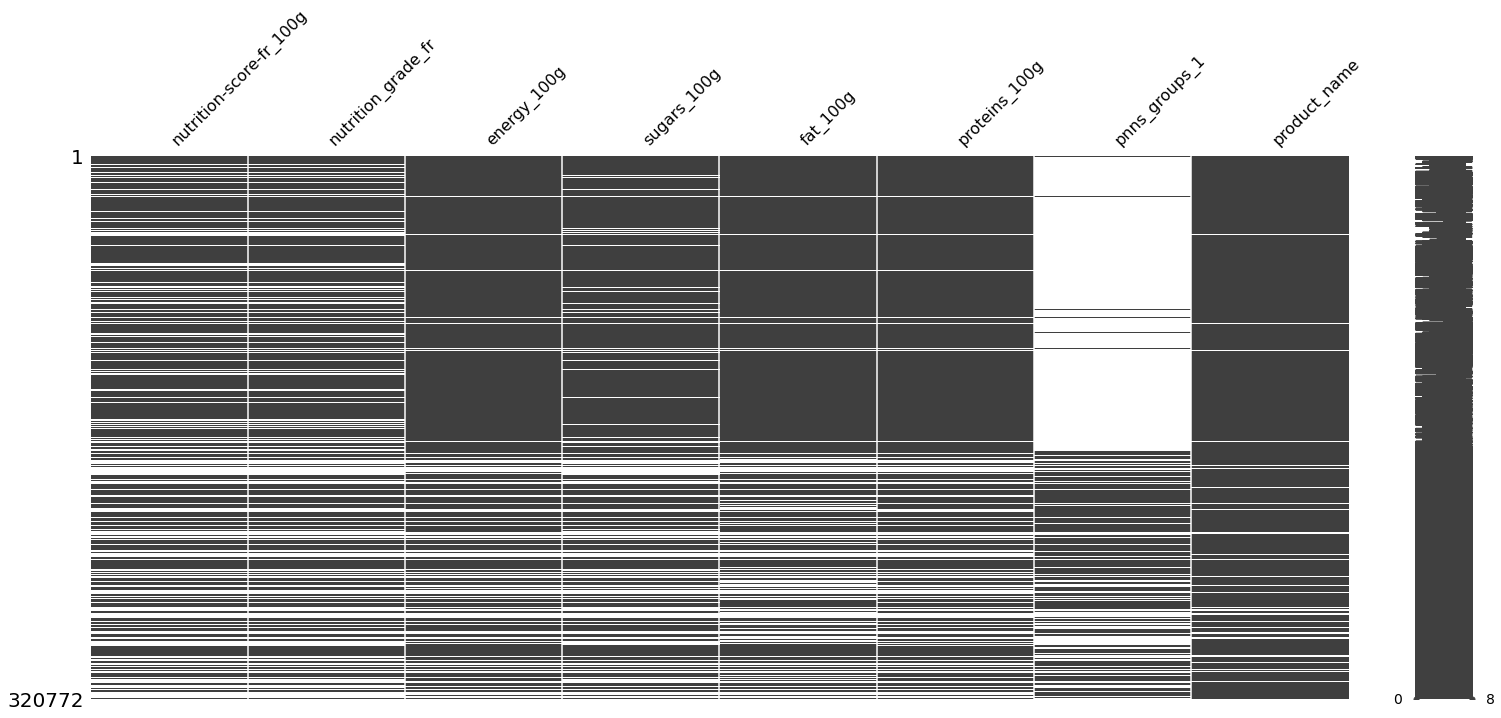

In [18]:
import missingno as msno

# Sous-ensemble de données avec les colonnes sélectionnées
cols_to_zoom = ['nutrition-score-fr_100g', 'nutrition_grade_fr', 'energy_100g', 'sugars_100g', 
                'fat_100g', 'proteins_100g',  'pnns_groups_1', 'product_name']
sub_nutri_app = nutri_app[cols_to_zoom]

# Matrice de visualisation avec les colonnes sélectionnées
msno.matrix(sub_nutri_app)


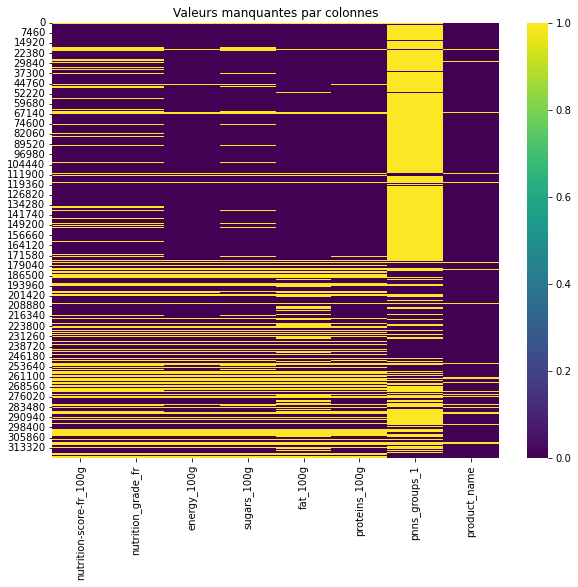

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Spécifier la taille de la figure
plt.figure(figsize=(10, 8))

# Créer un heatmap de valeurs manquantes
sns.heatmap(nutri_app[cols_to_zoom].isnull(), cmap='viridis')
plt.title('Valeurs manquantes par colonnes')
plt.show()



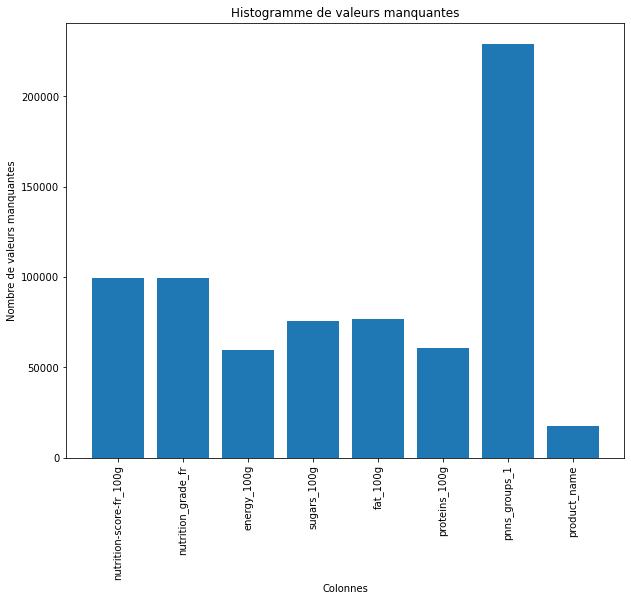

In [25]:
# Calculer le nombre de valeurs manquantes par colonne
null_counts = nutri_app[cols_to_zoom].isnull().sum()

# Créer un histogramme de valeurs manquantes
plt.figure(figsize=(10, 8))
plt.bar(null_counts.index, null_counts.values)
plt.xticks(rotation=90)
plt.xlabel('Colonnes')
plt.ylabel('Nombre de valeurs manquantes')
plt.title('Histogramme de valeurs manquantes')
plt.show()


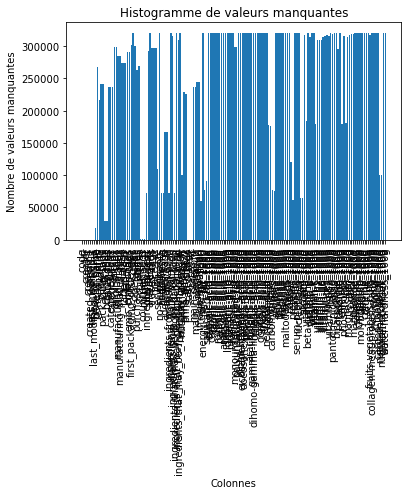

In [20]:
# Calculer le nombre de valeurs manquantes par colonne
null_counts = nutri_app.isnull().sum()

# Créer un histogramme de valeurs manquantes
plt.bar(null_counts.index, null_counts.values)
plt.xticks(rotation=90)
plt.xlabel('Colonnes')
plt.ylabel('Nombre de valeurs manquantes')
plt.title('Histogramme de valeurs manquantes')
plt.show()


In [12]:
nutri_app.columns.to_list()

['code',
 'url',
 'creator',
 'created_t',
 'created_datetime',
 'last_modified_t',
 'last_modified_datetime',
 'product_name',
 'generic_name',
 'quantity',
 'packaging',
 'packaging_tags',
 'brands',
 'brands_tags',
 'categories',
 'categories_tags',
 'categories_fr',
 'origins',
 'origins_tags',
 'manufacturing_places',
 'manufacturing_places_tags',
 'labels',
 'labels_tags',
 'labels_fr',
 'emb_codes',
 'emb_codes_tags',
 'first_packaging_code_geo',
 'cities',
 'cities_tags',
 'purchase_places',
 'stores',
 'countries',
 'countries_tags',
 'countries_fr',
 'ingredients_text',
 'allergens',
 'allergens_fr',
 'traces',
 'traces_tags',
 'traces_fr',
 'serving_size',
 'no_nutriments',
 'additives_n',
 'additives',
 'additives_tags',
 'additives_fr',
 'ingredients_from_palm_oil_n',
 'ingredients_from_palm_oil',
 'ingredients_from_palm_oil_tags',
 'ingredients_that_may_be_from_palm_oil_n',
 'ingredients_that_may_be_from_palm_oil',
 'ingredients_that_may_be_from_palm_oil_tags',
 'nutritio

>> Analyse : colonnes sur la nutrition, sur les produits, nutriments, origines... etc

>Objectif : affichage du type des colonnes du dataframe

In [13]:
nutri_app.dtypes

code                                           object
url                                            object
creator                                        object
created_t                                      object
created_datetime                               object
last_modified_t                                object
last_modified_datetime                         object
product_name                                   object
generic_name                                   object
quantity                                       object
packaging                                      object
packaging_tags                                 object
brands                                         object
brands_tags                                    object
categories                                     object
categories_tags                                object
categories_fr                                  object
origins                                        object
origins_tags                

> Objectif : afficher le nombre de doublons

In [14]:
duplicate = nutri_app[nutri_app.duplicated()]

In [15]:
duplicate

,code,url,creator,created_t,created_datetime,last_modified_t,last_modified_datetime,product_name,generic_name,quantity,packaging,packaging_tags,brands,brands_tags,categories,categories_tags,categories_fr,origins,origins_tags,manufacturing_places,manufacturing_places_tags,labels,labels_tags,labels_fr,emb_codes,...,chloride_100g,calcium_100g,phosphorus_100g,iron_100g,magnesium_100g,zinc_100g,copper_100g,manganese_100g,fluoride_100g,selenium_100g,chromium_100g,molybdenum_100g,iodine_100g,caffeine_100g,taurine_100g,ph_100g,fruits-vegetables-nuts_100g,collagen-meat-protein-ratio_100g,cocoa_100g,chlorophyl_100g,carbon-footprint_100g,nutrition-score-fr_100g,nutrition-score-uk_100g,glycemic-index_100g,water-hardness_100g


>> Analyse : pas de doublons dans ce dataset

> Objectif : afficher le nombre de lignes puis de colonnes

In [16]:
nutri_app.shape

(320772, 162)

>> Analyse : très large dataset avec beaucoup de lignes

>Objectif : afficher les données manquantes, avoir un aperçu du df (zones blanches correspoondant aux données manquantes et zones noires à celles remplies)

<AxesSubplot:>

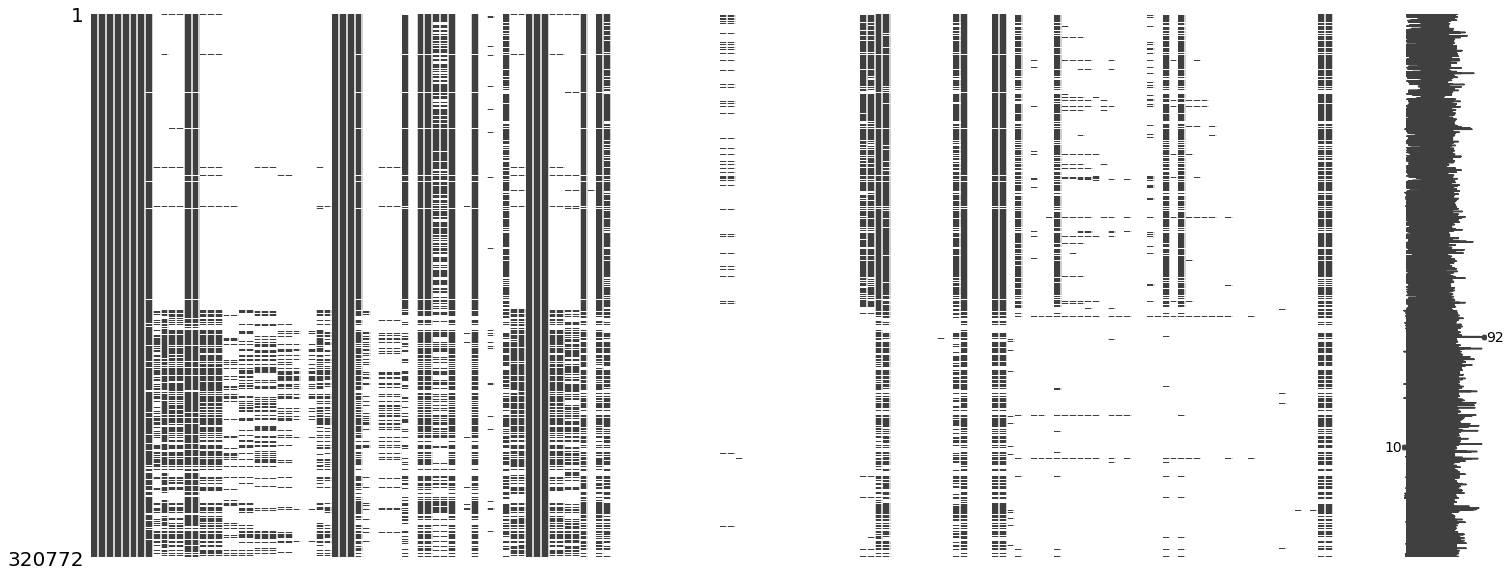

In [162]:
msno.matrix(nutri_app)

>>Analyse : beaucoup de blanc, donc de NaN et de valeurs manquantes,
>> On observe des zones, la 1ère avec données bien remplies dans les 8 premières colonnes puis 3/4 colonnes bien remplies un peu plus loin et ainsi de suite, mais surtout beaucoup de "zones blanches" et donc vides
On va essayer d'identifier ces zones bien remplies

> Objectif : donner en % le nombre de Nan dans l'ensemble du dataframe

In [163]:
nutri_app.isnull().sum().sum()/(nutri_app.size)


0.7622157263195134

>>Analyse : un taux élévé (presque 80%) de Nan dans l'ensemble du dataframe

>Objectif : afficher le détail du nombre de NaN pour chaque colonne (le total de NaN)

In [164]:
nutri_app.isna().sum()

code                                              23
url                                               23
creator                                            2
created_t                                          3
created_datetime                                   9
last_modified_t                                    0
last_modified_datetime                             0
product_name                                   17762
generic_name                                  267977
quantity                                      215953
packaging                                     241812
packaging_tags                                241811
brands                                         28412
brands_tags                                    28420
categories                                    236362
categories_tags                               236383
categories_fr                                 236361
origins                                       298582
origins_tags                                  

>>analyse : au moins 2 colonnes sans Nan et 2 avec 100% de NaN

>Objectif : afficher la distribution de ces valeurs manquantes dans le dataset avec en ordonnée le nombre de colonnes et en absisse le nombre de valeurs manquantes

>Aperçu du taux de remplissage des colonnes (nombre de NaN par colonnes) :

<AxesSubplot:>

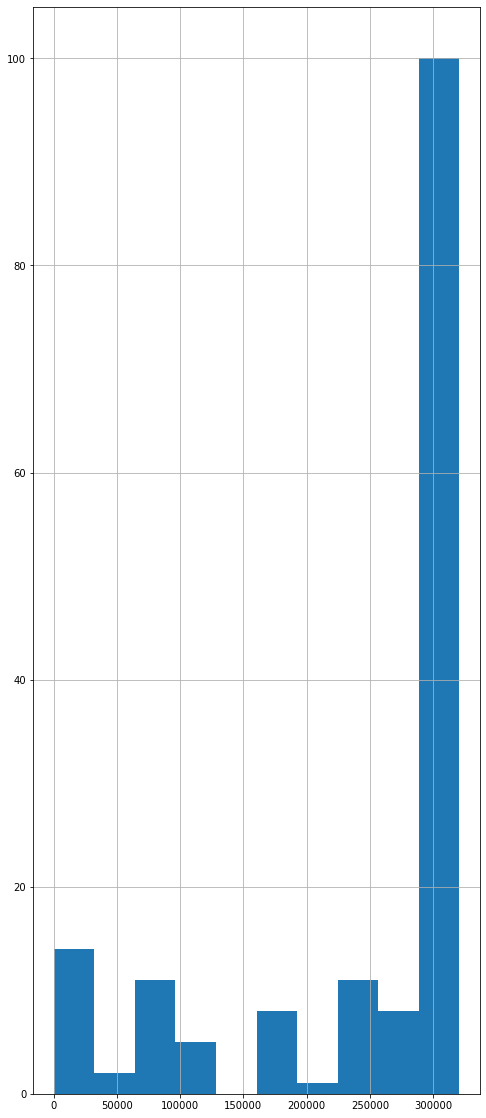

In [165]:
nan_histogram = nutri_app.apply(lambda x: x.isnull().value_counts()).T[True]
nan_histogram.hist() 

>>analyse : de très nombreuses colonnes avec 100% de valeurs manquantes (dernier baton) env 300 000 pour un total de 320772 lignes
>> Les autres batons sous la barre des 20 représentent le nombre de colonnes 

>> Tout à gauche on voit qu'il y a env 17 colonnes avec entre 0 valeurs manquantes et env la moitié de 50 000 (25 000) pour les 320772 lignes

>> Tout à droite on voit qu'il y a 100 colonnes avec env 300 000 lignes de NaN

> Objectif : afficher les colonnes contenant au moins un NaN

In [166]:
df_with_nulls = nutri_app[[col for col in nutri_app.columns if nutri_app[col].isna().sum() > 0]]

In [167]:
df_with_nulls

,code,url,creator,created_t,created_datetime,product_name,generic_name,quantity,packaging,packaging_tags,brands,brands_tags,categories,categories_tags,categories_fr,origins,origins_tags,manufacturing_places,manufacturing_places_tags,labels,labels_tags,labels_fr,emb_codes,emb_codes_tags,first_packaging_code_geo,cities,cities_tags,purchase_places,stores,countries,countries_tags,countries_fr,ingredients_text,allergens,allergens_fr,traces,traces_tags,traces_fr,serving_size,no_nutriments,additives_n,additives,additives_tags,additives_fr,ingredients_from_palm_oil_n,ingredients_from_palm_oil,ingredients_from_palm_oil_tags,ingredients_that_may_be_from_palm_oil_n,ingredients_that_may_be_from_palm_oil,ingredients_that_may_be_from_palm_oil_tags,...,proteins_100g,casein_100g,serum-proteins_100g,nucleotides_100g,salt_100g,sodium_100g,alcohol_100g,vitamin-a_100g,beta-carotene_100g,vitamin-d_100g,vitamin-e_100g,vitamin-k_100g,vitamin-c_100g,vitamin-b1_100g,vitamin-b2_100g,vitamin-pp_100g,vitamin-b6_100g,vitamin-b9_100g,folates_100g,vitamin-b12_100g,biotin_100g,pantothenic-acid_100g,silica_100g,bicarbonate_100g,potassium_100g,chloride_100g,calcium_100g,phosphorus_100g,iron_100g,magnesium_100g,zinc_100g,copper_100g,manganese_100g,fluoride_100g,selenium_100g,chromium_100g,molybdenum_100g,iodine_100g,caffeine_100g,taurine_100g,ph_100g,fruits-vegetables-nuts_100g,collagen-meat-protein-ratio_100g,cocoa_100g,chlorophyl_100g,carbon-footprint_100g,nutrition-score-fr_100g,nutrition-score-uk_100g,glycemic-index_100g,water-hardness_100g
0,3087,http://world-fr.openfoodfacts.org/produit/0000...,openfoodfacts-contributors,1474103866,2016-09-17T09:17:46Z,Farine de blé noir,NaN,1kg,NaN,NaN,Ferme t'y R'nao,ferme-t-y-r-nao,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,en:FR,en:france,France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4530,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489069957,2017-03-09T14:32:37Z,Banana Chips Sweetened (Whole),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,US,en:united-states,États-Unis,"Bananas, vegetable oil (coconut oil, corn oil ...",NaN,NaN,NaN,NaN,NaN,28 g (1 ONZ),NaN,0.0,[ bananas -> en:bananas ] [ vegetable-oil -...,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN,...,3.57,NaN,NaN,NaN,0.00000,0.000,NaN,0.0,NaN,NaN,NaN,NaN,0.0214,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,14.0,NaN,NaN
2,4559,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489069957,2017-03-09T14:32:37Z,Peanuts,NaN,NaN,NaN,NaN,Torn & Glasser,torn-glasser,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,US,en:united-states,États-Unis,"Peanuts, wheat flour, sugar, rice flour, tapio...",NaN,NaN,NaN,NaN,NaN,28 g (0.25 cup),NaN,0.0,[ peanuts -> en:peanuts ] [ wheat-flour -> ...,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN,...,17.86,NaN,NaN,NaN,0.63500,0.250,NaN,0.0,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.071,NaN,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN
3,16087,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489055731,2017-03-09T10:35:31Z,Organic Salted Nut Mix,NaN,NaN,NaN,NaN,Grizzlies,grizzlies,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,US,en:united-states,États-Unis,"Organic hazelnuts, organic cashews, organic wa...",NaN,NaN,NaN,NaN,NaN,28 g (0.25 cup),NaN,0.0,[ organic-hazelnuts -> en:organic-hazelnuts ...,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN,...,17.86,NaN,NaN,NaN,1.22428,0.482,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.143,NaN,0.00514,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

>> Analyse : presque 100% des colonnes contiennent des NaN (seules 2 n'en contiennent pas sur les 162 colonnes)

> Objectif : Affichage du nombre de lignes ou colonnes avec 0 NaN

In [168]:
df = nutri_app[~nutri_app.isnull().any(axis=1)]

In [169]:
df

,code,url,creator,created_t,created_datetime,last_modified_t,last_modified_datetime,product_name,generic_name,quantity,packaging,packaging_tags,brands,brands_tags,categories,categories_tags,categories_fr,origins,origins_tags,manufacturing_places,manufacturing_places_tags,labels,labels_tags,labels_fr,emb_codes,emb_codes_tags,first_packaging_code_geo,cities,cities_tags,purchase_places,stores,countries,countries_tags,countries_fr,ingredients_text,allergens,allergens_fr,traces,traces_tags,traces_fr,serving_size,no_nutriments,additives_n,additives,additives_tags,additives_fr,ingredients_from_palm_oil_n,ingredients_from_palm_oil,ingredients_from_palm_oil_tags,ingredients_that_may_be_from_palm_oil_n,...,proteins_100g,casein_100g,serum-proteins_100g,nucleotides_100g,salt_100g,sodium_100g,alcohol_100g,vitamin-a_100g,beta-carotene_100g,vitamin-d_100g,vitamin-e_100g,vitamin-k_100g,vitamin-c_100g,vitamin-b1_100g,vitamin-b2_100g,vitamin-pp_100g,vitamin-b6_100g,vitamin-b9_100g,folates_100g,vitamin-b12_100g,biotin_100g,pantothenic-acid_100g,silica_100g,bicarbonate_100g,potassium_100g,chloride_100g,calcium_100g,phosphorus_100g,iron_100g,magnesium_100g,zinc_100g,copper_100g,manganese_100g,fluoride_100g,selenium_100g,chromium_100g,molybdenum_100g,iodine_100g,caffeine_100g,taurine_100g,ph_100g,fruits-vegetables-nuts_100g,collagen-meat-protein-ratio_100g,cocoa_100g,chlorophyl_100g,carbon-footprint_100g,nutrition-score-fr_100g,nutrition-score-uk_100g,glycemic-index_100g,water-hardness_100g


In [170]:
df_without_nulls = nutri_app[[col for col in nutri_app.columns if nutri_app[col].isna().sum() == 0]]

In [171]:
df_without_nulls

,last_modified_t,last_modified_datetime
0,1474103893,2016-09-17T09:18:13Z
1,1489069957,2017-03-09T14:32:37Z
2,1489069957,2017-03-09T14:32:37Z
3,1489055731,2017-03-09T10:35:31Z
4,1489055653,2017-03-09T10:34:13Z
...,...,...
320767,1491244498,2017-04-03T18:34:58Z
320768,1491244499,2017-04-03T18:34:59Z
320769,1491244499,2017-04-03T18:34:59Z
320770,1492340089,2017-04-16T10:54:49Z


>>Analyse : on n'a aucune ligne contenant 0 NaN, et 2 colonnes seulement avec 0 NaN, les colonnes "last_modified_t" et "last_modified_datetime"

> Contenu du df nutri_app

In [172]:
nutri_app.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320772 entries, 0 to 320771
Columns: 162 entries, code to water-hardness_100g
dtypes: float64(106), object(56)
memory usage: 396.5+ MB


In [173]:
columns = nutri_app.columns.to_list()

In [174]:
columns

['code',
 'url',
 'creator',
 'created_t',
 'created_datetime',
 'last_modified_t',
 'last_modified_datetime',
 'product_name',
 'generic_name',
 'quantity',
 'packaging',
 'packaging_tags',
 'brands',
 'brands_tags',
 'categories',
 'categories_tags',
 'categories_fr',
 'origins',
 'origins_tags',
 'manufacturing_places',
 'manufacturing_places_tags',
 'labels',
 'labels_tags',
 'labels_fr',
 'emb_codes',
 'emb_codes_tags',
 'first_packaging_code_geo',
 'cities',
 'cities_tags',
 'purchase_places',
 'stores',
 'countries',
 'countries_tags',
 'countries_fr',
 'ingredients_text',
 'allergens',
 'allergens_fr',
 'traces',
 'traces_tags',
 'traces_fr',
 'serving_size',
 'no_nutriments',
 'additives_n',
 'additives',
 'additives_tags',
 'additives_fr',
 'ingredients_from_palm_oil_n',
 'ingredients_from_palm_oil',
 'ingredients_from_palm_oil_tags',
 'ingredients_that_may_be_from_palm_oil_n',
 'ingredients_that_may_be_from_palm_oil',
 'ingredients_that_may_be_from_palm_oil_tags',
 'nutritio

>Objectif : contenu des colonnes

>Objectif : suppression des colonnes avec taux de nan >= à 80%

In [175]:
df_nutri_app_seuil_nan = suppression_variable_seuil_taux_nan(nutri_app, 80)

Liste des variables éliminées :
['generic_name', 'origins', 'origins_tags', 'manufacturing_places', 'manufacturing_places_tags', 'labels', 'labels_tags', 'labels_fr', 'emb_codes', 'emb_codes_tags', 'first_packaging_code_geo', 'cities', 'cities_tags', 'purchase_places', 'stores', 'allergens', 'allergens_fr', 'traces', 'traces_tags', 'traces_fr', 'no_nutriments', 'ingredients_from_palm_oil', 'ingredients_from_palm_oil_tags', 'ingredients_that_may_be_from_palm_oil', 'ingredients_that_may_be_from_palm_oil_tags', 'nutrition_grade_uk', 'energy-from-fat_100g', 'butyric-acid_100g', 'caproic-acid_100g', 'caprylic-acid_100g', 'capric-acid_100g', 'lauric-acid_100g', 'myristic-acid_100g', 'palmitic-acid_100g', 'stearic-acid_100g', 'arachidic-acid_100g', 'behenic-acid_100g', 'lignoceric-acid_100g', 'cerotic-acid_100g', 'montanic-acid_100g', 'melissic-acid_100g', 'monounsaturated-fat_100g', 'polyunsaturated-fat_100g', 'omega-3-fat_100g', 'alpha-linolenic-acid_100g', 'eicosapentaenoic-acid_100g', 'do

In [176]:
df_nutri_app_seuil_nan.shape

(320772, 54)

In [177]:
df_nutri_app_seuil_nan.head(3)

,code,url,creator,created_t,created_datetime,last_modified_t,last_modified_datetime,product_name,quantity,packaging,packaging_tags,brands,brands_tags,categories,categories_tags,categories_fr,countries,countries_tags,countries_fr,ingredients_text,serving_size,additives_n,additives,additives_tags,additives_fr,ingredients_from_palm_oil_n,ingredients_that_may_be_from_palm_oil_n,nutrition_grade_fr,pnns_groups_1,pnns_groups_2,states,states_tags,states_fr,main_category,main_category_fr,image_url,image_small_url,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition-score-uk_100g
0,3087,http://world-fr.openfoodfacts.org/produit/0000...,openfoodfacts-contributors,1474103866,2016-09-17T09:17:46Z,1474103893,2016-09-17T09:18:13Z,Farine de blé noir,1kg,NaN,NaN,Ferme t'y R'nao,ferme-t-y-r-nao,NaN,NaN,NaN,en:FR,en:france,France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"en:to-be-completed, en:nutrition-facts-to-be-c...","en:to-be-completed,en:nutrition-facts-to-be-co...","A compléter,Informations nutritionnelles à com...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4530,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489069957,2017-03-09T14:32:37Z,1489069957,2017-03-09T14:32:37Z,Banana Chips Sweetened (Whole),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,US,en:united-states,États-Unis,"Bananas, vegetable oil (coconut oil, corn oil ...",28 g (1 ONZ),0.0,[ bananas -> en:bananas ] [ vegetable-oil -...,NaN,NaN,0.0,0.0,d,NaN,NaN,"en:to-be-completed, en:nutrition-facts-complet...","en:to-be-completed,en:nutrition-facts-complete...","A compléter,Informations nutritionnelles compl...",NaN,NaN,NaN,NaN,2243.0,28.57,28.57,0.0,0.018,64.29,14.29,3.6,3.57,0.000,0.00,0.0,0.0214,0.000,0.00129,14.0,14.0
2,4559,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489069957,2017-03-09T14:32:37Z,1489069957,2017-03-09T14:32:37Z,Peanuts,NaN,NaN,NaN,Torn & Glasser,torn-glasser,NaN,NaN,NaN,US,en:united-states,États-Unis,"Peanuts, wheat flour, sugar, rice flour, tapio...",28 g (0.25 cup),0.0,[ peanuts -> en:peanuts ] [ wheat-flour -> ...,NaN,NaN,0.0,0.0,b,NaN,NaN,"en:to-be-completed, en:nutrition-facts-complet...","en:to-be-completed,en:nutrition-facts-complete...","A compléter,Informations nutritionnelles compl...",NaN,NaN,NaN,NaN,1941.0,17.86,0.00,0.0,0.000,60.71,17.86,7.1,17.86,0.635,0.25,0.0,0.0000,0.071,0.00129,0.0,0.0


> Objectif : filtrer les lignes qui sont sans valeurs nan dans ce nouveau dataset et explorer le contenu de chaque colonnes pour un produit donné afin d'étudier un aperçu et trouver une idée d'application

In [178]:
selected_rows = df_nutri_app_seuil_nan[~df_nutri_app_seuil_nan.isnull().any(axis=1)]

In [179]:
selected_rows.head(2)

,code,url,creator,created_t,created_datetime,last_modified_t,last_modified_datetime,product_name,quantity,packaging,packaging_tags,brands,brands_tags,categories,categories_tags,categories_fr,countries,countries_tags,countries_fr,ingredients_text,serving_size,additives_n,additives,additives_tags,additives_fr,ingredients_from_palm_oil_n,ingredients_that_may_be_from_palm_oil_n,nutrition_grade_fr,pnns_groups_1,pnns_groups_2,states,states_tags,states_fr,main_category,main_category_fr,image_url,image_small_url,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition-score-uk_100g
579,36559,http://world-fr.openfoodfacts.org/produit/0003...,tacinte,1421942083,2015-01-22T15:54:43Z,1437482582,2015-07-21T12:43:02Z,Mac 'n Cheese,397 g,box,box,Joe's Diner,joe-s-diner,Microwave meals,"en:meals,en:microwave-meals","Plats préparés,Plats préparés à réchauffer au ...",United States,en:united-states,États-Unis,"COOKED ELBOW MACARONI (WATER, ENRICHED SEMOLIN...",198 g,5.0,[ cooked-elbow-macaroni -> en:cooked-elbow-ma...,"en:e375,en:e101,en:e509,en:e160,en:e160b","E375 - Acide nicotinique,E101 - Riboflavine,E5...",0.0,0.0,c,Composite foods,One-dish meals,"en:to-be-checked, en:complete, en:nutrition-fa...","en:to-be-checked,en:complete,en:nutrition-fact...","A vérifier,Complet,Informations nutritionnelle...",en:meals,Plats préparés,http://fr.openfoodfacts.org/images/products/00...,http://fr.openfoodfacts.org/images/products/00...,761.0,7.58,4.04,0.0,0.0202,21.2,1.52,0.505,8.08,0.757,0.2980,0.000061,0.0,0.101,0.000727,4.0,4.0
1163,9542018061,http://world-fr.openfoodfacts.org/produit/0009...,stephane,1438277323,2015-07-30T17:28:43Z,1489067172,2017-03-09T13:46:12Z,Creation Hazelnut Torte Milk Chocolate,3.5 OZ (100g),Card,card,"Lindt, Lindt & Sprungli Sas","lindt,lindt-sprungli-sas","Sugary snacks,Chocolates,Milk chocolates","en:sugary-snacks,en:chocolates,en:milk-chocolates","Snacks sucrés,Chocolats,Chocolats au lait",United States,en:united-states,États-Unis,"Sugar, almond and hazelnut praline (_almonds_,...",Four pieces (40 g),1.0,[ sugar -> en:sugar ] [ almond-and-hazelnut...,en:e322,E322 - Lécithines,0.0,0.0,e,Sugary snacks,Chocolate products,"en:to-be-checked, en:complete, en:nutrition-fa...","en:to-be-checked,en:complete,en:nutrition-fact...","A vérifier,Complet,Informations nutritionnelle...",en:chocolates,Chocolats,http://fr.openfoodfacts.org/images/products/00...,http://fr.openfoodfacts.org/images/products/00...,2300.0,32.50,20.00,0.0,0.0125,55.0,52.50,2.500,7.50,0.159,0.0625,0.000000,0.0,0.200,0.000900,23.0,23.0


In [180]:
selected_rows.iloc[1]

code                                                                              9542018061
url                                        http://world-fr.openfoodfacts.org/produit/0009...
creator                                                                             stephane
created_t                                                                         1438277323
created_datetime                                                        2015-07-30T17:28:43Z
last_modified_t                                                                   1489067172
last_modified_datetime                                                  2017-03-09T13:46:12Z
product_name                                          Creation Hazelnut Torte Milk Chocolate
quantity                                                                       3.5 OZ (100g)
packaging                                                                               Card
packaging_tags                                                        

In [181]:
selected_rows.shape

(354, 54)

>354 lignes complètement remplies

In [182]:
selected_rows.head(3).to_csv("aperçu_colonnes_gardees.csv")

In [183]:
selected_rows.columns.to_list()

['code',
 'url',
 'creator',
 'created_t',
 'created_datetime',
 'last_modified_t',
 'last_modified_datetime',
 'product_name',
 'quantity',
 'packaging',
 'packaging_tags',
 'brands',
 'brands_tags',
 'categories',
 'categories_tags',
 'categories_fr',
 'countries',
 'countries_tags',
 'countries_fr',
 'ingredients_text',
 'serving_size',
 'additives_n',
 'additives',
 'additives_tags',
 'additives_fr',
 'ingredients_from_palm_oil_n',
 'ingredients_that_may_be_from_palm_oil_n',
 'nutrition_grade_fr',
 'pnns_groups_1',
 'pnns_groups_2',
 'states',
 'states_tags',
 'states_fr',
 'main_category',
 'main_category_fr',
 'image_url',
 'image_small_url',
 'energy_100g',
 'fat_100g',
 'saturated-fat_100g',
 'trans-fat_100g',
 'cholesterol_100g',
 'carbohydrates_100g',
 'sugars_100g',
 'fiber_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g',
 'vitamin-a_100g',
 'vitamin-c_100g',
 'calcium_100g',
 'iron_100g',
 'nutrition-score-fr_100g',
 'nutrition-score-uk_100g']

In [184]:
df_nutri_app_seuil_nan.to_csv

<bound method NDFrame.to_csv of                  code                                                url                     creator   created_t      created_datetime last_modified_t last_modified_datetime                                       product_name quantity  packaging packaging_tags           brands      brands_tags    categories                                    categories_tags                                      categories_fr countries    countries_tags countries_fr                                   ingredients_text      serving_size  additives_n                                          additives                                     additives_tags                                       additives_fr  ingredients_from_palm_oil_n  ingredients_that_may_be_from_palm_oil_n nutrition_grade_fr pnns_groups_1  \
0                3087  http://world-fr.openfoodfacts.org/produit/0000...  openfoodfacts-contributors  1474103866  2016-09-17T09:17:46Z      1474103893   2016-09-17T09:18:13Z   

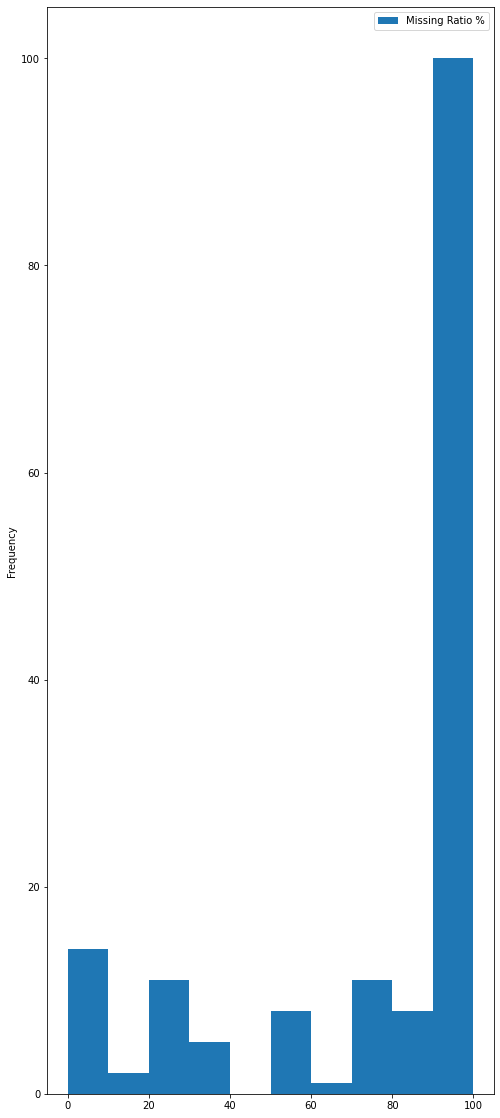

In [185]:
plot_nans2(nutri_app)
plot_width, plot_height = (5,7)
plt.rcParams['figure.figsize'] = (plot_width,plot_height)


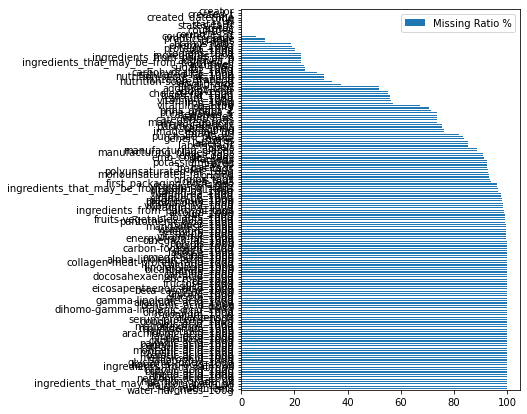

In [186]:
plot_nans(nutri_app)
plot_width, plot_height = (8,50)
plt.rcParams['figure.figsize'] = (plot_width,plot_height)


In [187]:
df_nutri_app_seuil_nan.describe()

,additives_n,ingredients_from_palm_oil_n,ingredients_that_may_be_from_palm_oil_n,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition-score-uk_100g
count,248939.000000,248939.000000,248939.000000,2.611130e+05,243891.000000,229554.000000,143298.000000,144090.000000,243588.000000,244971.000000,200886.000000,259922.000000,255510.000000,255463.000000,137554.000000,140867.000000,141050.000000,140462.000000,221210.000000,221210.000000
mean,1.936024,0.019659,0.055246,1.141915e+03,12.730379,5.129932,0.073476,0.020071,32.073981,16.003484,2.862111,7.075940,2.028624,0.798815,0.000397,0.023367,0.125163,0.003652,9.165535,9.058049
std,2.502019,0.140524,0.269207,6.447154e+03,17.578747,8.014238,1.540223,0.358062,29.731719,22.327284,12.867578,8.409054,128.269454,50.504428,0.073278,2.236451,3.318263,0.214408,9.055903,9.183589
min,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,-3.570000,0.000000,0.000000,-17.860000,-6.700000,-800.000000,0.000000,0.000000,-0.000340,-0.002100,0.000000,-0.000260,-15.000000,-15.000000
25%,0.000000,0.000000,0.000000,3.770000e+02,0.000000,0.000000,0.000000,0.000000,6.000000,1.300000,0.000000,0.700000,0.063500,0.025000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
50%,1.000000,0.000000,0.000000,1.100000e+03,5.000000,1.790000,0.000000,0.000000,20.600000,5.710000,1.500000,4.760000,0.581660,0.229000,0.000000,0.000000,0.035000,0.001010,10.000000,9.000000
75%,3.000000,0.000000,0.000000,1.674000e+03,20.000000,7.140000,0.000000,0.020000,58.330000,24.000000,3.600000,10.000000,1.374140,0.541000,0.000107,0.003700,0.106000,0.002400,16.000000,16.000000
max,31.000000,2.000000,6.000000,3.251373e+06,714.290000,550.000000,369.000000,95.238000,2916.670000,3520.000000,5380.000000,430.000000,64312.800000,25320.000000,26.700000,716.981100,694.737000,50.000000,40.000000,40.000000


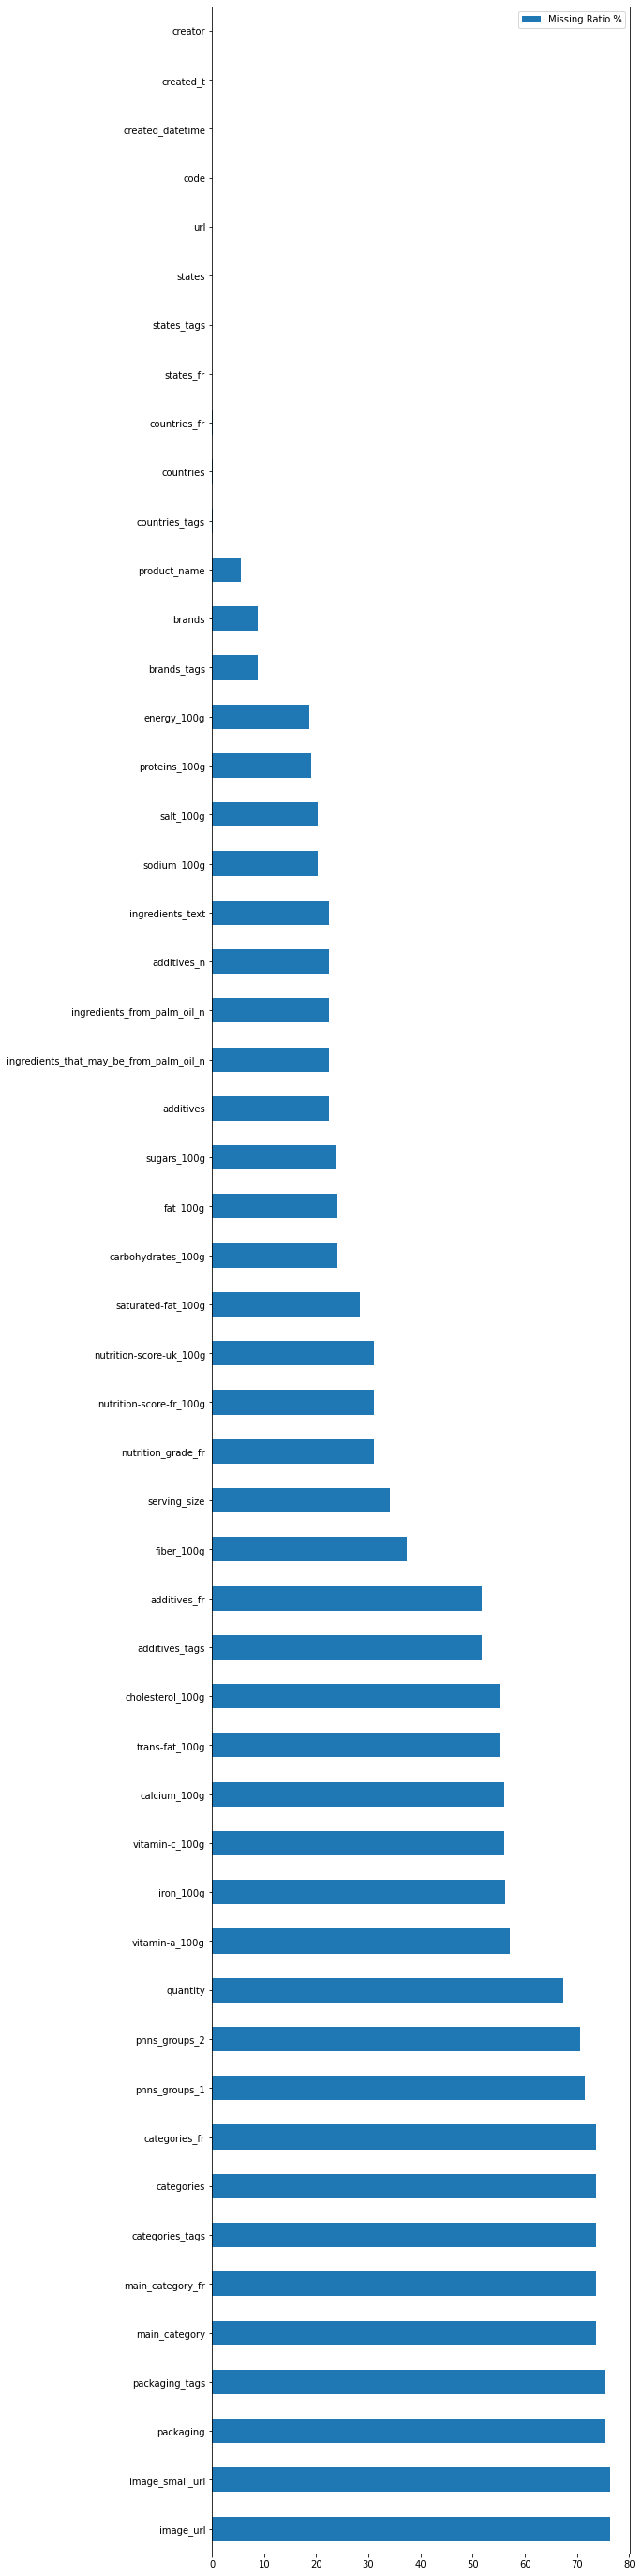

In [188]:
plot_nans(df_nutri_app_seuil_nan)
plot_width, plot_height = (8,20)
plt.rcParams['figure.figsize'] = (plot_width,plot_height)

In [189]:
def description_variables(dataframe, type_var='cat'):
    df_taille = dataframe.shape[0]

    if type_var == 'num':
        desc_var = dataframe.describe()
    elif type_var == 'cat':
        desc_var = dataframe.describe(exclude=[np.number])
    else:
        desc_var = dataframe.describe(include='all')

    desc_type = pd.DataFrame(desc_var.dtypes, columns=['type']).T
    nb_nan = df_taille - desc_var.loc['count'].T
    pourcentage_nan = nb_nan * 100 / df_taille
    desc_nan = pd.DataFrame([nb_nan, pourcentage_nan],
                            index=['nb_nan', '%_nan'])
    desc_var = pd.concat([desc_type, desc_nan, desc_var])

    return desc_var
  
    

description_variables(df_nutri_app_seuil_nan, type_var='num')

,additives_n,ingredients_from_palm_oil_n,ingredients_that_may_be_from_palm_oil_n,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition-score-uk_100g
type,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
nb_nan,71833.0,71833.0,71833.0,59659.0,76881.0,91218.0,177474.0,176682.0,77184.0,75801.0,119886.0,60850.0,65262.0,65309.0,183218.0,179905.0,179722.0,180310.0,99562.0,99562.0
%_nan,22.393787,22.393787,22.393787,18.598568,23.967491,28.437021,55.327148,55.080244,24.061951,23.630803,37.37421,18.96986,20.345292,20.359944,57.117828,56.085007,56.027958,56.211265,31.038245,31.038245
count,248939.0,248939.0,248939.0,261113.0,243891.0,229554.0,143298.0,144090.0,243588.0,244971.0,200886.0,259922.0,255510.0,255463.0,137554.0,140867.0,141050.0,140462.0,221210.0,221210.0
mean,1.936024,0.019659,0.055246,1141.914605,12.730379,5.129932,0.073476,0.020071,32.073981,16.003484,2.862111,7.07594,2.028624,0.798815,0.000397,0.023367,0.125163,0.003652,9.165535,9.058049
std,2.502019,0.140524,0.269207,6447.154093,17.578747,8.014238,1.540223,0.358062,29.731719,22.327284,12.867578,8.409054,128.269454,50.504428,0.073278,2.236451,3.318263,0.214408,9.055903,9.183589
min,0.0,0.0,0.0,0.0,0.0,0.0,-3.57,0.0,0.0,-17.86,-6.7,-800.0,0.0,0.0,-0.00034,-0.0021,0.0,-0.00026,-15.0,-15.0
25%,0.0,0.0,0.0,377.0,0.0,0.0,0.0,0.0,6.0,1.3,0.0,0.7,0.0635,0.025,0.0,0.0,0.0,0.0,1.0,1.0
50%,1.0,0.0,0.0,1100.0,5.0,1.79,0.0,0.0,20.6,5.71,1.5,4.76,0.58166,0.229,0.0,0.0,0.035,0.00101,10.0,9.0
75%,3.0,0.0,0.0,1674.0,20.0,7.14,0.0,0.02,58.33,24.0,3.6,10.0,1.37414,0.541,0.000107,0.0037,0.106,0.0024,16.0,16.0


In [190]:
description_variables(df_nutri_app_seuil_nan, type_var='cat')

,code,url,creator,created_t,created_datetime,last_modified_t,last_modified_datetime,product_name,quantity,packaging,packaging_tags,brands,brands_tags,categories,categories_tags,categories_fr,countries,countries_tags,countries_fr,ingredients_text,serving_size,additives,additives_tags,additives_fr,nutrition_grade_fr,pnns_groups_1,pnns_groups_2,states,states_tags,states_fr,main_category,main_category_fr,image_url,image_small_url
type,int64,object,object,int64,object,int64,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object
nb_nan,23.0,23.0,2.0,3.0,9.0,0.0,0.0,17762.0,215953.0,241812.0,241811.0,28412.0,28420.0,236362.0,236383.0,236361.0,280.0,280.0,280.0,71810.0,109441.0,71867.0,166092.0,166092.0,99562.0,229259.0,226281.0,46.0,46.0,46.0,236406.0,236406.0,244936.0,244936.0
%_nan,0.00717,0.00717,0.000623,0.000935,0.002806,0.0,0.0,5.537266,67.322896,75.384385,75.384073,8.857382,8.859876,73.685359,73.691906,73.685047,0.087289,0.087289,0.087289,22.386617,34.118003,22.404387,51.778834,51.778834,31.038245,71.471014,70.542628,0.01434,0.01434,0.01434,73.699076,73.699076,76.358286,76.358286
count,320749,320749,320770,320769,320763,320772,320772,303010,104819,78960,78961,292360,292352,84410,84389,84411,320492,320492,320492,248962,211331,248905,154680,154680,221210,91513,94491,320726,320726,320726,84366,84366,75836,75836
unique,320638,320749,3535,189636,189568,180639,180495,221347,13826,14547,12064,58784,50253,36982,21142,21152,1434,725,722,205520,25423,196069,41537,41537,5,14,42,1021,1021,1021,3543,3543,75836,75836
top,24463061071,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489077120,2017-03-09T10:37:09Z,1439141742,2015-08-09T17:35:42Z,Ice Cream,500 g,Carton,"sachet,plastique",Carrefour,carrefour,"Snacks sucrés,Biscuits et gâteaux,Biscuits","en:sugary-snacks,en:biscuits-and-cakes,en:bisc...","Snacks sucrés,Biscuits et gâteaux,Biscuits",US,en:united-states,États-Unis,"Carbonated water, natural flavor.",240 ml (8 fl oz),[ extra-virgin-olive-oil -> en:extra-virgin-o...,en:e322,E322 - Lécithines,d,unknown,unknown,"en:to-be-completed, en:nutrition-facts-complet...","en:to-be-completed,en:nutrition-facts-complete...","A compléter,Informations nutritionnelles compl...",en:beverages,Boissons,http://fr.openfoodfacts.org/images/products/00...,http://fr.openfoodfacts.org/images/products/00...
freq,2,1,169868,20,20,33,33,410,4669,2153,3959,2978,3149,301,802,802,169928,172998,172998,222,5496,397,8264,8264,62763,22624,22624,168905,168905,168905,6054,6054,1,1


In [191]:
columns_quantitative = df_nutri_app_seuil_nan.select_dtypes(include = ['int32','float64']).columns

> Objectif faire un scatter plot + ciblé

In [192]:
columns_quantitative.to_list()

['additives_n',
 'ingredients_from_palm_oil_n',
 'ingredients_that_may_be_from_palm_oil_n',
 'energy_100g',
 'fat_100g',
 'saturated-fat_100g',
 'trans-fat_100g',
 'cholesterol_100g',
 'carbohydrates_100g',
 'sugars_100g',
 'fiber_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g',
 'vitamin-a_100g',
 'vitamin-c_100g',
 'calcium_100g',
 'iron_100g',
 'nutrition-score-fr_100g',
 'nutrition-score-uk_100g']

> Appli : Input du “product name” dans la barre de recherche, Premier onglet composition avec nutriscore, Deuxieme onglet recommendation avec aliments similaires du + au moins sain, Nutriscore qui s’afficherait à côté de l’image du produit recommandé

•Nettoyer un peu le JN et filtrer en python les colonnes sélectionnées --> on obtient un sous dataframe

•Déterminer les seuils de valeurs aberrantes pour les différentes colonnes (mail si besoin)

•ARemplacer les valeurs aberrantes par des nan (dans une logique de fonction/ré utilisation de code)


> Sous-dataframe avec colonnes sélectionnées

In [193]:
cols_nutri = ['product_name','energy_100g','fat_100g','saturated-fat_100g','trans-fat_100g','cholesterol_100g','carbohydrates_100g','sugars_100g','fiber_100g','proteins_100g','salt_100g','sodium_100g','vitamin-a_100g','vitamin-c_100g','calcium_100g','iron_100g','pnns_groups_1','pnns_groups_2','categories','categories_tags','categories_fr','image_url','nutrition-score-fr_100g','nutrition_grade_fr']

In [194]:
nutri_app_new = df_nutri_app_seuil_nan[cols_nutri]

>> sous-dataframe :

In [195]:
nutri_app_new

,product_name,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,pnns_groups_1,pnns_groups_2,categories,categories_tags,categories_fr,image_url,nutrition-score-fr_100g,nutrition_grade_fr
0,Farine de blé noir,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Banana Chips Sweetened (Whole),2243.0,28.57,28.57,0.0,0.018,64.29,14.29,3.6,3.57,0.00000,0.000,0.0,0.0214,0.000,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,14.0,d
2,Peanuts,1941.0,17.86,0.00,0.0,0.000,60.71,17.86,7.1,17.86,0.63500,0.250,0.0,0.0000,0.071,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,0.0,b
3,Organic Salted Nut Mix,2540.0,57.14,5.36,NaN,NaN,17.86,3.57,7.1,17.86,1.22428,0.482,NaN,NaN,0.143,0.00514,NaN,NaN,NaN,NaN,NaN,NaN,12.0,d
4,Organic Polenta,1552.0,1.43,NaN,NaN,NaN,77.14,NaN,5.7,8.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320767,Tomato & ricotta,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320768,"Mint Melange Tea A Blend Of Peppermint, Lemon ...",0.0,0.00,0.00,0.0,0.000,0.00,0.00,0.0,0.00,0.00000,0.000,0.0,0.0000,0.000,0.00000,NaN,NaN,NaN,NaN,NaN,NaN,0.0,b
320769,乐吧泡菜味薯片,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Salty snacks,Appetizers,Potato chips,"en:salty-snacks,en:appetizers,en:chips-and-fri...","Snacks salés,Apéritif,Chips et frites,Chips,Ch...",http://fr.openfoodfacts.org/images/products/99...,NaN,NaN
320770,Tomates aux Vermicelles,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [196]:
pd.set_option("display.max_columns", 25)

In [197]:
nutri_app.columns

Index(['code', 'url', 'creator', 'created_t', 'created_datetime', 'last_modified_t', 'last_modified_datetime', 'product_name', 'generic_name', 'quantity',
       ...
       'ph_100g', 'fruits-vegetables-nuts_100g', 'collagen-meat-protein-ratio_100g', 'cocoa_100g', 'chlorophyl_100g', 'carbon-footprint_100g', 'nutrition-score-fr_100g', 'nutrition-score-uk_100g', 'glycemic-index_100g', 'water-hardness_100g'], dtype='object', length=162)

>éliminer valeurs abberantes > 100g et <0

> Déterminer les seuils de valeurs aberrantes pour les différentes colonnes 

In [198]:
nutri_app_new.columns

Index(['product_name', 'energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'calcium_100g', 'iron_100g', 'pnns_groups_1', 'pnns_groups_2', 'categories', 'categories_tags', 'categories_fr', 'image_url', 'nutrition-score-fr_100g', 'nutrition_grade_fr'], dtype='object')

In [199]:
nutri_app_new['energy_100g'] = [np.nan if val >
                           3765 else np.nan if val <
                     0 else val for val in nutri_app_new['energy_100g']]

/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_84918/3572676990.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nutri_app_new['energy_100g'] = [np.nan if val >


In [200]:
cols_100g = nutri_app_new.columns[nutri_app_new.columns.str.endswith('_100g')].to_list()
cols_100g.remove('nutrition-score-fr_100g')
cols_100g.remove('energy_100g')
for col in cols_100g:
    nutri_app_new[col] = [np.nan if val > 100 else np.nan if val <
                     0 else val for val in nutri_app_new[col]]

/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_84918/1875582600.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nutri_app_new[col] = [np.nan if val > 100 else np.nan if val <


In [201]:
nutri_app_new.describe()

,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g
count,260559.000000,243887.000000,229551.000000,143289.000000,144090.000000,243569.000000,244952.000000,200881.000000,259918.000000,255352.000000,255429.000000,137553.000000,140863.000000,141040.000000,140461.000000,221210.000000
mean,1119.544326,12.725256,5.125925,0.067172,0.020071,32.055323,15.985449,2.832473,7.079409,1.588497,0.647145,0.000397,0.014563,0.102023,0.003653,9.165535
std,789.475736,17.503695,7.913684,0.945020,0.358062,29.140680,21.165362,4.588272,8.156552,6.242531,2.656343,0.073279,0.461423,0.585288,0.214409,9.055903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-15.000000
25%,373.150000,0.000000,0.000000,0.000000,0.000000,6.000000,1.300000,0.000000,0.700000,0.063500,0.025000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,1100.000000,5.000000,1.790000,0.000000,0.000000,20.600000,5.710000,1.500000,4.760000,0.580000,0.229000,0.000000,0.000000,0.035000,0.001010,10.000000
75%,1674.000000,20.000000,7.140000,0.000000,0.020000,58.330000,24.000000,3.600000,10.000000,1.371600,0.541000,0.000107,0.003700,0.106000,0.002400,16.000000
max,3764.000000,100.000000,100.000000,100.000000,95.238000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,26.700000,100.000000,99.006000,50.000000,40.000000


<AxesSubplot:>

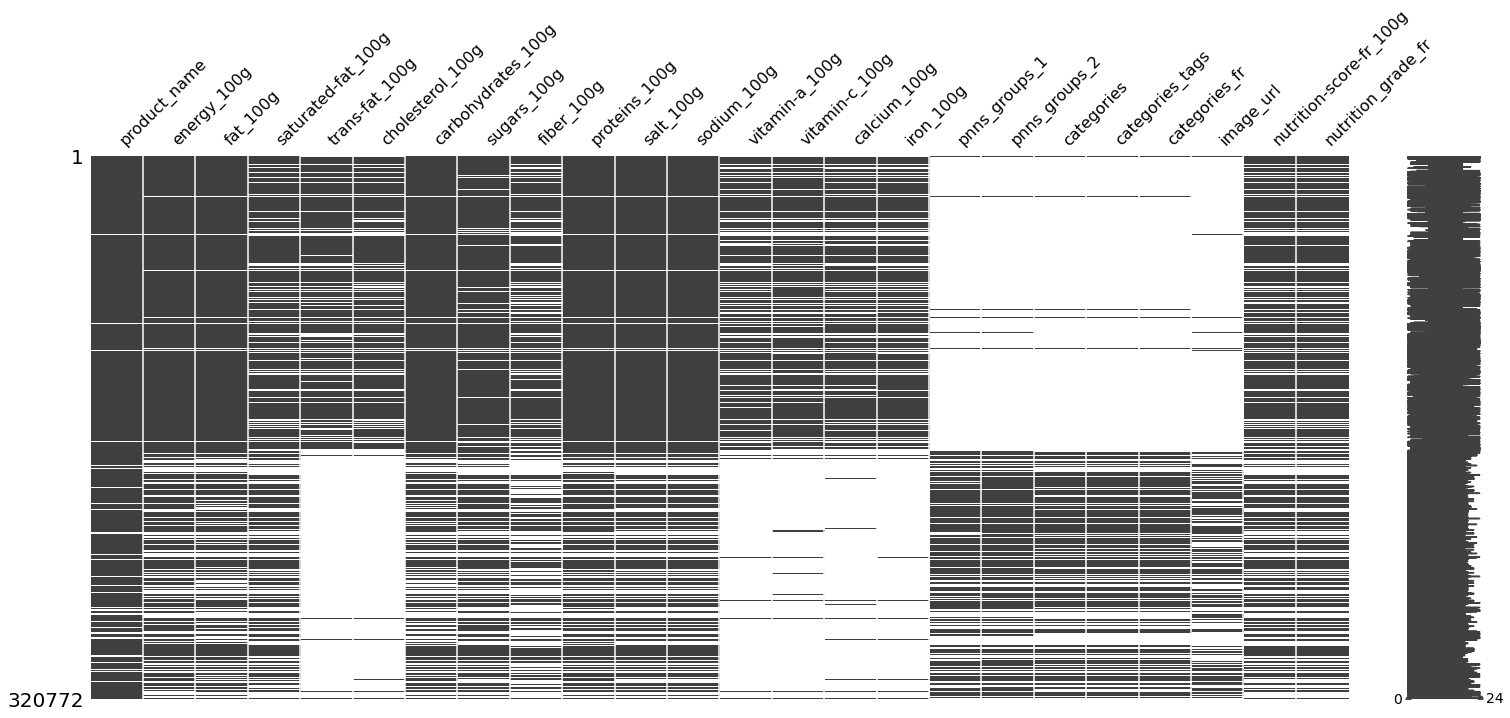

In [202]:
msno.matrix(nutri_app_new)

In [203]:
percentage = 90.0

min_ = int(((100 - percentage)/100)*nutri_app_new.shape[1]+1)
nutri_app_new_seuil = df.dropna (axis=0, thresh=min_)

suppr lignes avec taux de nan >90%

In [204]:
nutri_app_new_seuil = nutri_app_new.loc[:, nutri_app_new.isnull().mean() < .9]

In [205]:
nutri_app_new_seuil

,product_name,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,pnns_groups_1,pnns_groups_2,categories,categories_tags,categories_fr,image_url,nutrition-score-fr_100g,nutrition_grade_fr
0,Farine de blé noir,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Banana Chips Sweetened (Whole),2243.0,28.57,28.57,0.0,0.018,64.29,14.29,3.6,3.57,0.00000,0.000,0.0,0.0214,0.000,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,14.0,d
2,Peanuts,1941.0,17.86,0.00,0.0,0.000,60.71,17.86,7.1,17.86,0.63500,0.250,0.0,0.0000,0.071,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,0.0,b
3,Organic Salted Nut Mix,2540.0,57.14,5.36,NaN,NaN,17.86,3.57,7.1,17.86,1.22428,0.482,NaN,NaN,0.143,0.00514,NaN,NaN,NaN,NaN,NaN,NaN,12.0,d
4,Organic Polenta,1552.0,1.43,NaN,NaN,NaN,77.14,NaN,5.7,8.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320767,Tomato & ricotta,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320768,"Mint Melange Tea A Blend Of Peppermint, Lemon ...",0.0,0.00,0.00,0.0,0.000,0.00,0.00,0.0,0.00,0.00000,0.000,0.0,0.0000,0.000,0.00000,NaN,NaN,NaN,NaN,NaN,NaN,0.0,b
320769,乐吧泡菜味薯片,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Salty snacks,Appetizers,Potato chips,"en:salty-snacks,en:appetizers,en:chips-and-fri...","Snacks salés,Apéritif,Chips et frites,Chips,Ch...",http://fr.openfoodfacts.org/images/products/99...,NaN,NaN
320770,Tomates aux Vermicelles,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<AxesSubplot:>

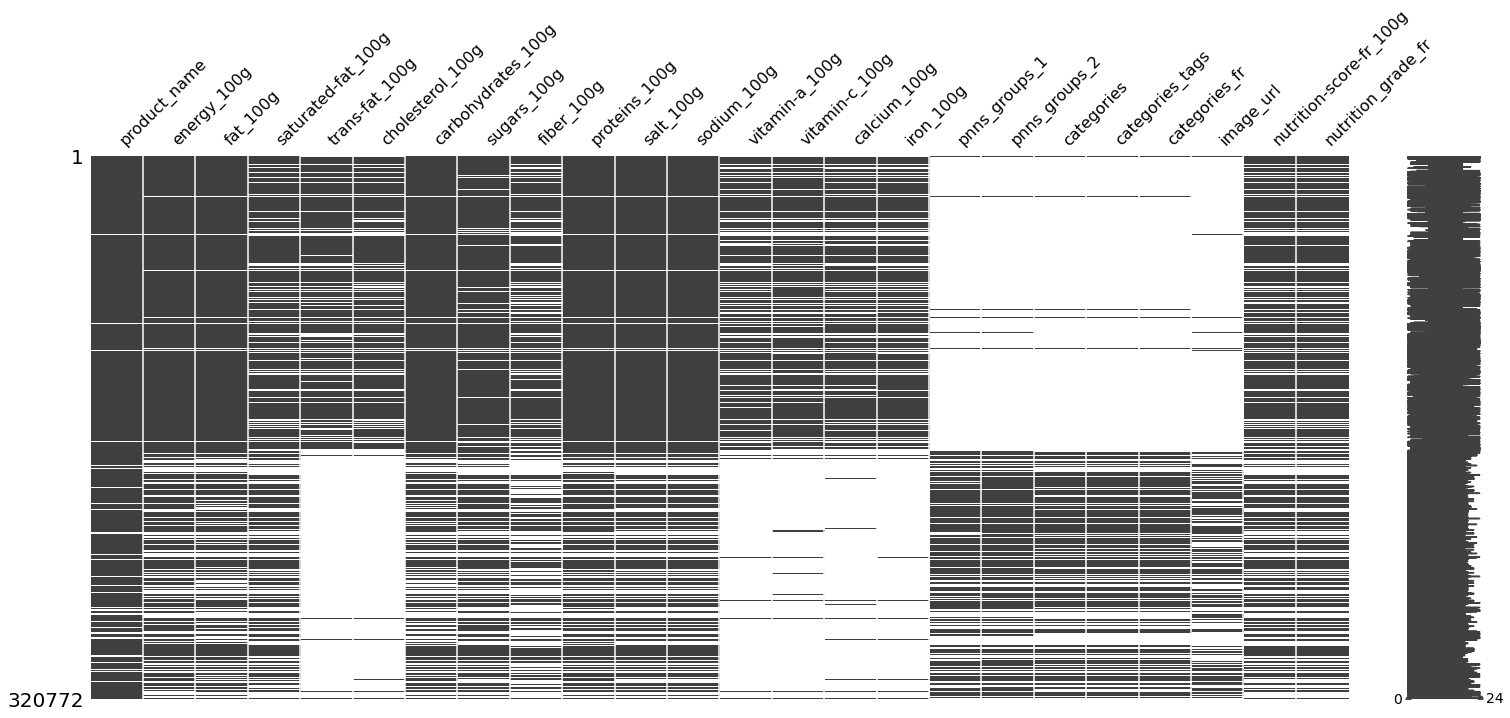

In [206]:
msno.matrix(nutri_app_new_seuil)

In [207]:
taux_de_nan_par_colonne(nutri_app_new_seuil)

product_name                5.537266
energy_100g                18.771277
fat_100g                   23.968738
saturated-fat_100g         28.437956
trans-fat_100g             55.329954
cholesterol_100g           55.080244
carbohydrates_100g         24.067874
sugars_100g                23.636726
fiber_100g                 37.375768
proteins_100g              18.971107
salt_100g                  20.394548
sodium_100g                20.370544
vitamin-a_100g             57.118140
vitamin-c_100g             56.086254
calcium_100g               56.031075
iron_100g                  56.211577
pnns_groups_1              71.471014
pnns_groups_2              70.542628
categories                 73.685359
categories_tags            73.691906
categories_fr              73.685047
image_url                  76.358286
nutrition-score-fr_100g    31.038245
nutrition_grade_fr         31.038245
dtype: float64

In [208]:
nutri_app_new_seuil_nan = nutri_app_new_seuil.isnull().sum()/len(nutri_app_new_seuil)*100
nutri_app_new_seuil_nan = pd.DataFrame(nutri_app_new_seuil_nan)
nutri_app_new_seuil_nan

,0
product_name,5.537266
energy_100g,18.771277
fat_100g,23.968738
saturated-fat_100g,28.437956
trans-fat_100g,55.329954
cholesterol_100g,55.080244
carbohydrates_100g,24.067874
sugars_100g,23.636726
fiber_100g,37.375768
proteins_100g,18.971107


In [209]:
description_variables(nutri_app_new_seuil, type_var='cat')

,product_name,pnns_groups_1,pnns_groups_2,categories,categories_tags,categories_fr,image_url,nutrition_grade_fr
type,object,object,object,object,object,object,object,object
nb_nan,17762.0,229259.0,226281.0,236362.0,236383.0,236361.0,244936.0,99562.0
%_nan,5.537266,71.471014,70.542628,73.685359,73.691906,73.685047,76.358286,31.038245
count,303010,91513,94491,84410,84389,84411,75836,221210
unique,221347,14,42,36982,21142,21152,75836,5
top,Ice Cream,unknown,unknown,"Snacks sucrés,Biscuits et gâteaux,Biscuits","en:sugary-snacks,en:biscuits-and-cakes,en:bisc...","Snacks sucrés,Biscuits et gâteaux,Biscuits",http://fr.openfoodfacts.org/images/products/00...,d
freq,410,22624,22624,301,802,802,1,62763


In [210]:
description_variables(nutri_app_new_seuil, type_var='num')

,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g
type,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
nb_nan,60213.0,76885.0,91221.0,177483.0,176682.0,77203.0,75820.0,119891.0,60854.0,65420.0,65343.0,183219.0,179909.0,179732.0,180311.0,99562.0
%_nan,18.771277,23.968738,28.437956,55.329954,55.080244,24.067874,23.636726,37.375768,18.971107,20.394548,20.370544,57.11814,56.086254,56.031075,56.211577,31.038245
count,260559.0,243887.0,229551.0,143289.0,144090.0,243569.0,244952.0,200881.0,259918.0,255352.0,255429.0,137553.0,140863.0,141040.0,140461.0,221210.0
mean,1119.544326,12.725256,5.125925,0.067172,0.020071,32.055323,15.985449,2.832473,7.079409,1.588497,0.647145,0.000397,0.014563,0.102023,0.003653,9.165535
std,789.475736,17.503695,7.913684,0.94502,0.358062,29.14068,21.165362,4.588272,8.156552,6.242531,2.656343,0.073279,0.461423,0.585288,0.214409,9.055903
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-15.0
25%,373.15,0.0,0.0,0.0,0.0,6.0,1.3,0.0,0.7,0.0635,0.025,0.0,0.0,0.0,0.0,1.0
50%,1100.0,5.0,1.79,0.0,0.0,20.6,5.71,1.5,4.76,0.58,0.229,0.0,0.0,0.035,0.00101,10.0
75%,1674.0,20.0,7.14,0.0,0.02,58.33,24.0,3.6,10.0,1.3716,0.541,0.000107,0.0037,0.106,0.0024,16.0


In [211]:
columns_quantitative_new = nutri_app_new_seuil.select_dtypes(include = ['int32','float64']).columns

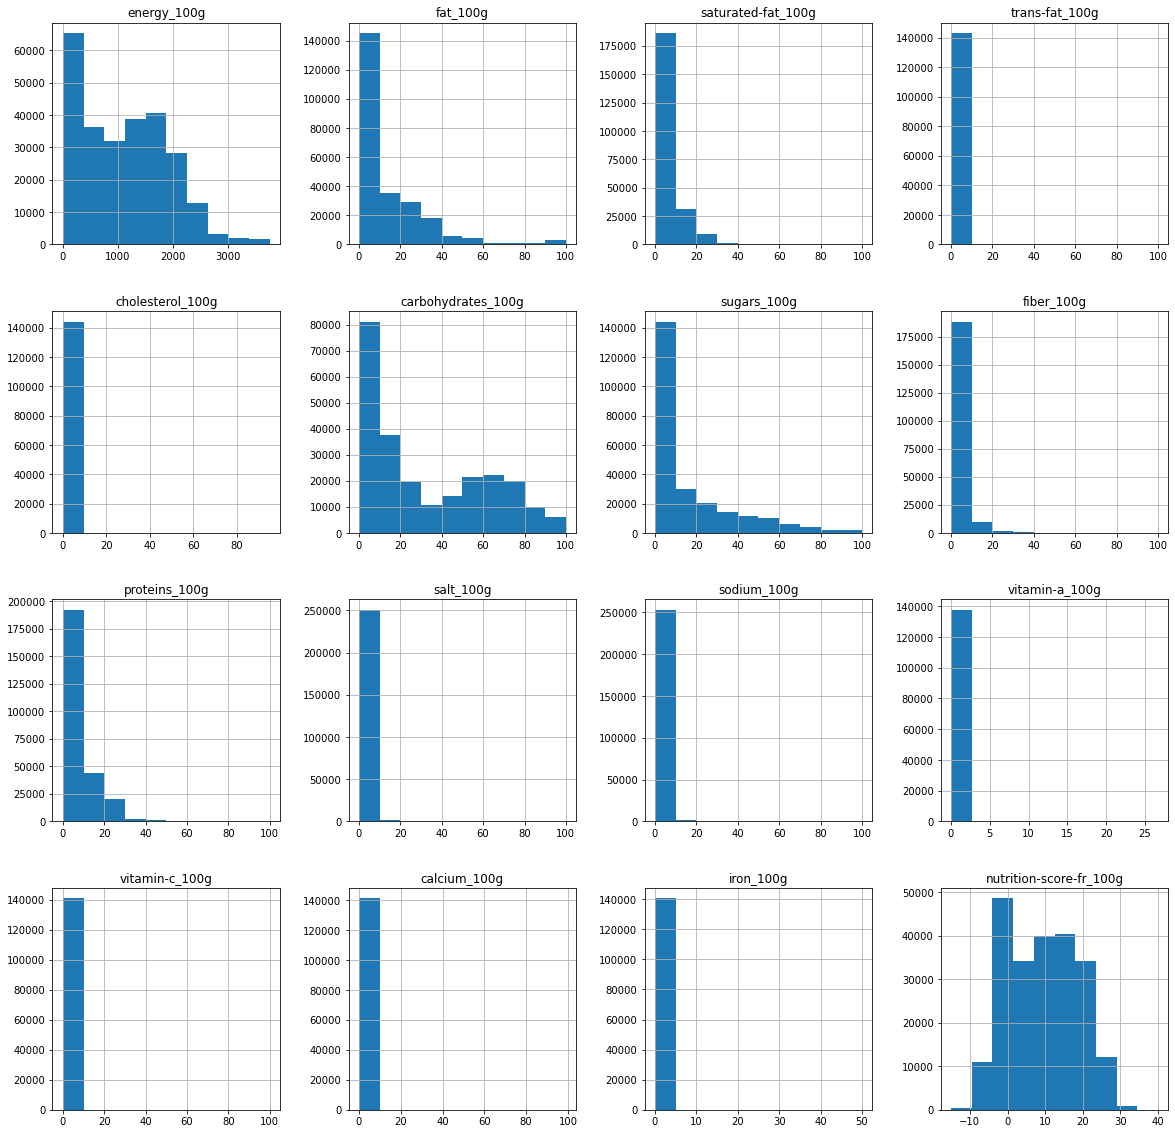

In [212]:
nutri_app_new_seuil.hist(figsize=(20,20))
plt.show()

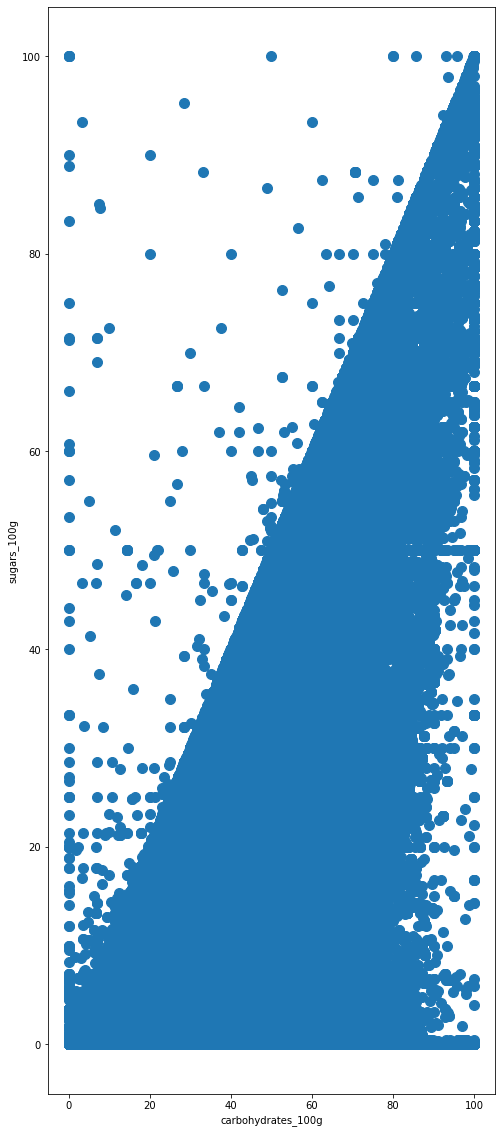

In [213]:
nutri_app_new_seuil.plot.scatter(x = 'carbohydrates_100g', y = 'sugars_100g', s = 100);

In [214]:
nutri_app_new_seuil_new_ = nutri_app_new_seuil.drop(columns=["categories_tags","categories_fr","image_url"])
nutri_app_new_seuil_new_
new_dataset_col_classifier = [
 'energy_100g',
 'fat_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g',
 'pnns_groups_1']

new_dataset_col_regressor = [
 'energy_100g',
 'fat_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g',
 'pnns_groups_1']

new_dataset_col_classifier2 = [
 'energy_100g',
 'fat_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g',
 'pnns_groups_1']

new_dataset_col_regressor2 = [
 'energy_100g',
 'fat_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g',
 'pnns_groups_1']
 
df_new_dataset_classifier = nutri_app_new_seuil_new_.filter(['energy_100g','fat_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g',
 'pnns_groups_1'], axis=1)


<AxesSubplot:>

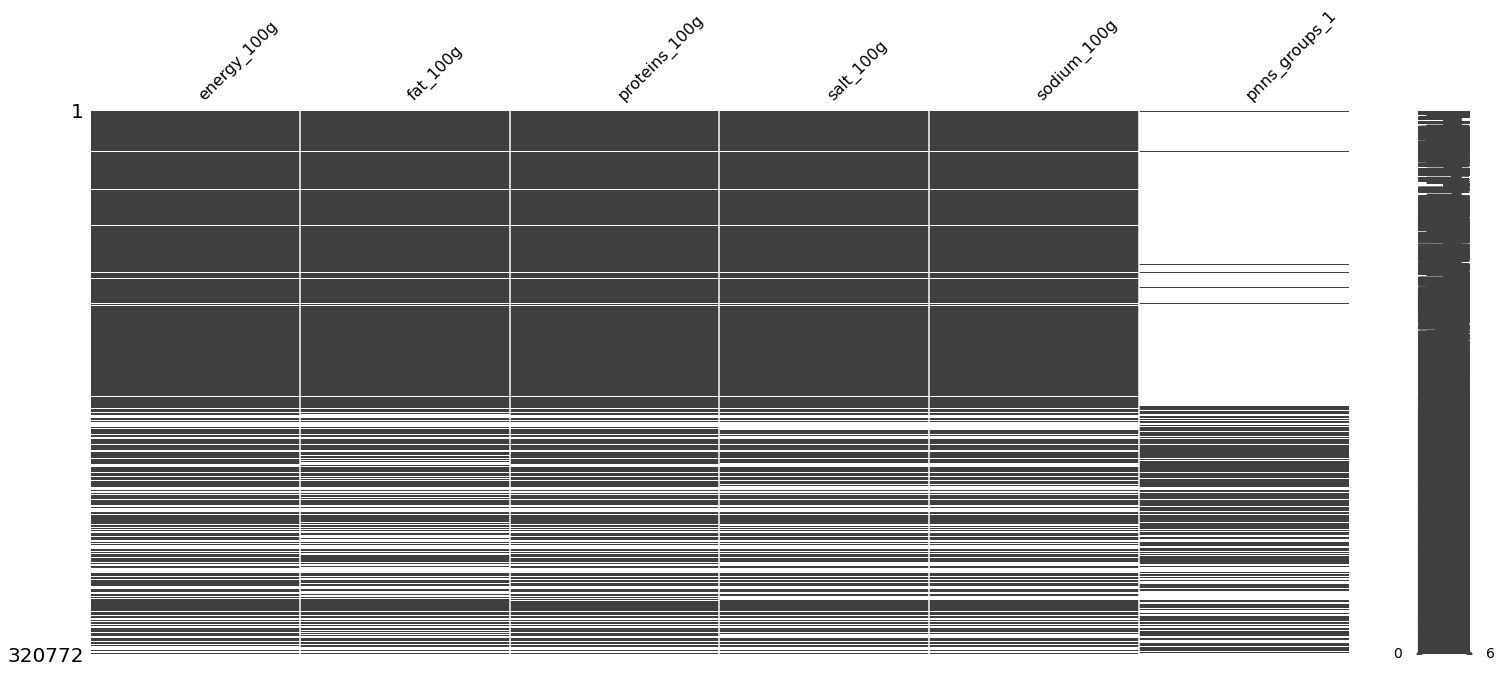

In [215]:
msno.matrix(df_new_dataset_classifier)

In [216]:
perc = 75.0 
min_count =  int(((100-perc)/100)*df_new_dataset_classifier.shape[1] + 1)
mod_df_new_dataset_classifier2 = df_new_dataset_classifier.dropna( axis=0, 
                    thresh=min_count)
df_new_dataset_classifier = nutri_app_new_seuil_new_.filter(['energy_100g','fat_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g',
 'pnns_groups_1'], axis=1)

df_studies = df_new_dataset_classifier.dropna(subset=['energy_100g',
 'fat_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g','pnns_groups_1'])
df_studies = df_studies[df_studies["pnns_groups_1"]!="unknown"]
df_studies

,energy_100g,fat_100g,proteins_100g,salt_100g,sodium_100g,pnns_groups_1
174,1210.0,12.00,22.000,2.16000,0.850000,Fruits and vegetables
175,1520.0,14.40,4.790,0.92200,0.363000,Sugary snacks
180,1090.0,10.70,3.330,0.64700,0.255000,Sugary snacks
185,478.0,6.79,5.360,0.49900,0.196000,Composite foods
186,751.0,10.20,33.900,0.73500,0.289000,Fish Meat Eggs
...,...,...,...,...,...,...
320692,2111.0,53.30,1.700,1.75006,0.689000,Fat and sauces
320693,660.0,6.90,0.300,0.54102,0.213000,Fat and sauces
320702,1031.0,1.30,0.004,0.00100,0.000394,Sugary snacks
320751,1643.0,2.80,13.000,0.68000,0.267717,Cereals and potatoes


<AxesSubplot:>

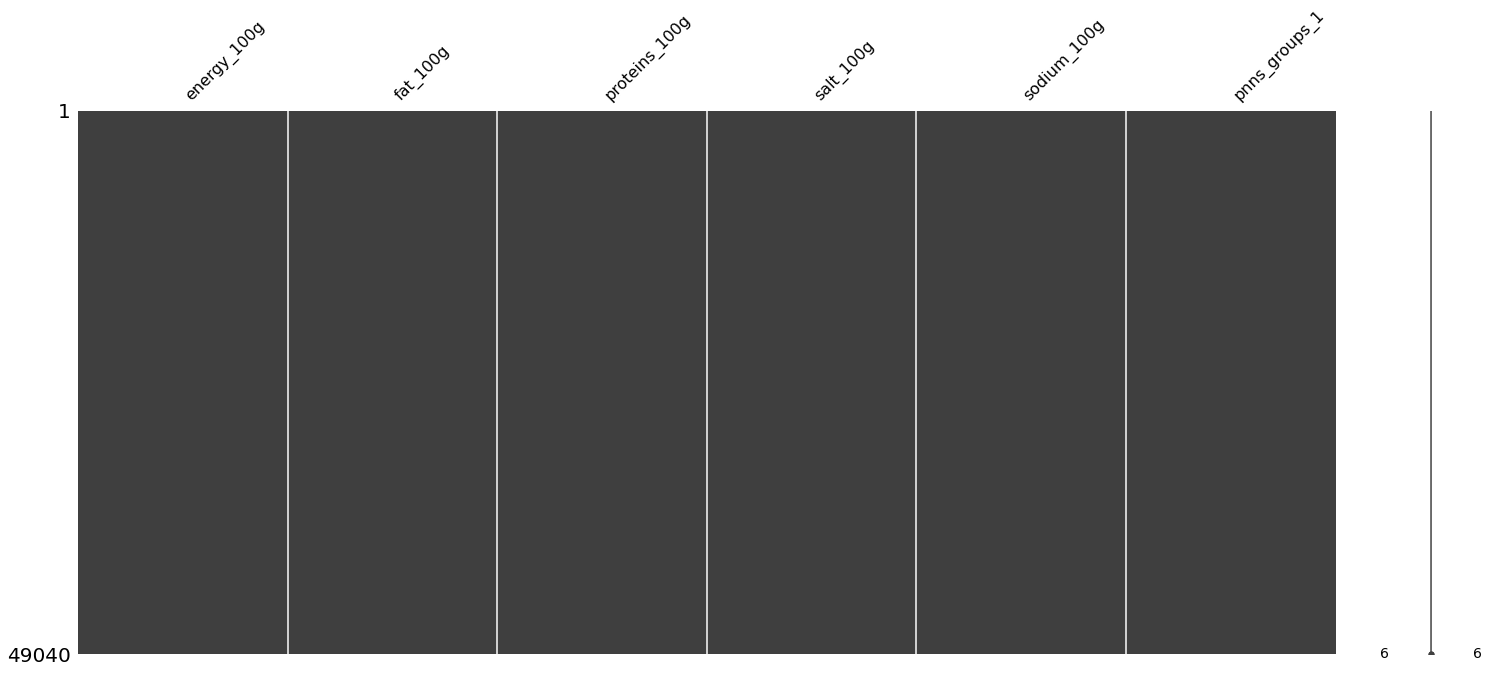

In [217]:
msno.matrix(df_studies)

In [218]:
df_studies["pnns_groups_1"].nunique()

13

In [219]:
df_studies['pnns_groups_1'].unique()

array(['Fruits and vegetables', 'Sugary snacks', 'Composite foods',
       'Fish Meat Eggs', 'Beverages', 'Cereals and potatoes',
       'Milk and dairy products', 'Fat and sauces', 'Salty snacks',
       'fruits-and-vegetables', 'sugary-snacks', 'cereals-and-potatoes',
       'salty-snacks'], dtype=object)

In [220]:
df_studies['pnns_groups_1'] = df_studies['pnns_groups_1'].astype('category')
df_studies['pnns_groups_1_label'] = df_studies['pnns_groups_1'].cat.codes

In [221]:
df_studies

,energy_100g,fat_100g,proteins_100g,salt_100g,sodium_100g,pnns_groups_1,pnns_groups_1_label
174,1210.0,12.00,22.000,2.16000,0.850000,Fruits and vegetables,5
175,1520.0,14.40,4.790,0.92200,0.363000,Sugary snacks,8
180,1090.0,10.70,3.330,0.64700,0.255000,Sugary snacks,8
185,478.0,6.79,5.360,0.49900,0.196000,Composite foods,2
186,751.0,10.20,33.900,0.73500,0.289000,Fish Meat Eggs,4
...,...,...,...,...,...,...,...
320692,2111.0,53.30,1.700,1.75006,0.689000,Fat and sauces,3
320693,660.0,6.90,0.300,0.54102,0.213000,Fat and sauces,3
320702,1031.0,1.30,0.004,0.00100,0.000394,Sugary snacks,8
320751,1643.0,2.80,13.000,0.68000,0.267717,Cereals and potatoes,1


In [222]:
df_studies["pnns_groups_1"].unique()

['Fruits and vegetables', 'Sugary snacks', 'Composite foods', 'Fish Meat Eggs', 'Beverages', ..., 'Salty snacks', 'fruits-and-vegetables', 'sugary-snacks', 'cereals-and-potatoes', 'salty-snacks']
Length: 13
Categories (13, object): ['Beverages', 'Cereals and potatoes', 'Composite foods', 'Fat and sauces', ..., 'cereals-and-potatoes', 'fruits-and-vegetables', 'salty-snacks', 'sugary-snacks']

In [223]:
df_studies.drop(columns="pnns_groups_1", inplace=True)
df_studies

,energy_100g,fat_100g,proteins_100g,salt_100g,sodium_100g,pnns_groups_1_label
174,1210.0,12.00,22.000,2.16000,0.850000,5
175,1520.0,14.40,4.790,0.92200,0.363000,8
180,1090.0,10.70,3.330,0.64700,0.255000,8
185,478.0,6.79,5.360,0.49900,0.196000,2
186,751.0,10.20,33.900,0.73500,0.289000,4
...,...,...,...,...,...,...
320692,2111.0,53.30,1.700,1.75006,0.689000,3
320693,660.0,6.90,0.300,0.54102,0.213000,3
320702,1031.0,1.30,0.004,0.00100,0.000394,8
320751,1643.0,2.80,13.000,0.68000,0.267717,1


>bloc de code classifier:

In [224]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier

# Create features and target
X = df_studies.drop("pnns_groups_1_label", axis =1)
y_classifier = df_studies["pnns_groups_1_label"]


# Create training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_classifier, train_size=0.8)

# Initialize a model with 3 neighbors
knn = KNeighborsClassifier(n_neighbors=3)

# Fit and predict
knn.fit(X_train, y_train)
knn.score(X_test, y_test)




0.7511215334420881

In [225]:
predictions = knn.predict(X_test)

In [226]:
predictions

array([4, 0, 0, ..., 4, 2, 2], dtype=int8)

In [227]:
from sklearn.neighbors import KNeighborsRegressor

# Create features and target
X = df_studies.drop('energy_100g', axis=1)
y = df_studies.energy_100g

# Train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8)

# Initialize kNN
knn = KNeighborsRegressor(n_neighbors=5)

# Fit and score
knn.fit(X_train, y_train)
knn.score(X_test, y_test)

0.9244796436806912

In [228]:
df_studies

,energy_100g,fat_100g,proteins_100g,salt_100g,sodium_100g,pnns_groups_1_label
174,1210.0,12.00,22.000,2.16000,0.850000,5
175,1520.0,14.40,4.790,0.92200,0.363000,8
180,1090.0,10.70,3.330,0.64700,0.255000,8
185,478.0,6.79,5.360,0.49900,0.196000,2
186,751.0,10.20,33.900,0.73500,0.289000,4
...,...,...,...,...,...,...
320692,2111.0,53.30,1.700,1.75006,0.689000,3
320693,660.0,6.90,0.300,0.54102,0.213000,3
320702,1031.0,1.30,0.004,0.00100,0.000394,8
320751,1643.0,2.80,13.000,0.68000,0.267717,1


In [229]:
X

,fat_100g,proteins_100g,salt_100g,sodium_100g,pnns_groups_1_label
174,12.00,22.000,2.16000,0.850000,5
175,14.40,4.790,0.92200,0.363000,8
180,10.70,3.330,0.64700,0.255000,8
185,6.79,5.360,0.49900,0.196000,2
186,10.20,33.900,0.73500,0.289000,4
...,...,...,...,...,...
320692,53.30,1.700,1.75006,0.689000,3
320693,6.90,0.300,0.54102,0.213000,3
320702,1.30,0.004,0.00100,0.000394,8
320751,2.80,13.000,0.68000,0.267717,1


In [230]:
predicted = knn.predict(X_test)

In [231]:
predicted

array([1721.8 ,  136.72, 2240.8 , ...,  529.4 ,  326.2 ,  766.8 ])

In [232]:

def plot_complexity_curve(k_list, knn_model, X_train, X_test, y_train, y_test):
    
    train_scores = []
    test_scores = []
    
    # For each k
    for k in k_list:
        # Initialize, fit, predict
        knn = knn_model(k)
        
        knn.fit(X_train, y_train)
        
        train_scores.append(knn.score(X_train, y_train))
        test_scores.append(knn.score(X_test, y_test))

    # Plot
    fig, ax = plt.subplots()
    
    ax.plot(k_list, train_scores, label='Training Accuracy', color='red')
    ax.plot(k_list, test_scores, label='Testing Accuracy', color='black')

    ax.set(title='k-NN with Different Values for $k$',
           xlabel='Number of Neighbors',
           ylabel='Accuracy')
    
    ax.legend()

> plot for Classifier

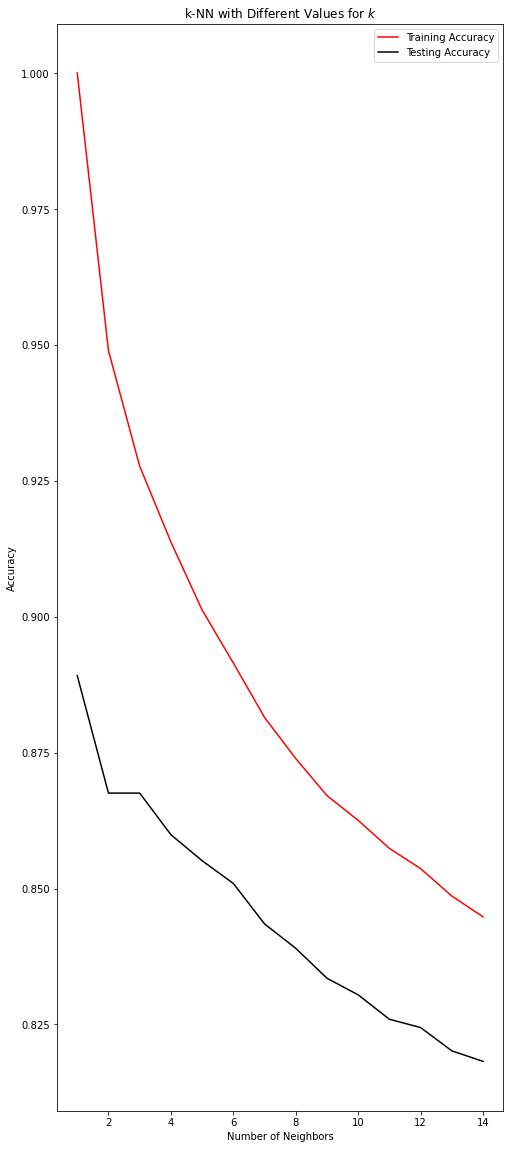

In [233]:
neighbors = np.arange(1, 15)

# Create features and target
X = df_studies.select_dtypes(exclude=['object'])
y = df_studies.pnns_groups_1_label

# Train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8)

plot_complexity_curve(neighbors, KNeighborsClassifier, 
                    X_train, X_test, y_train, y_test)

> plot for regressor

In [234]:
df_studies.isna().sum()

energy_100g            0
fat_100g               0
proteins_100g          0
salt_100g              0
sodium_100g            0
pnns_groups_1_label    0
dtype: int64

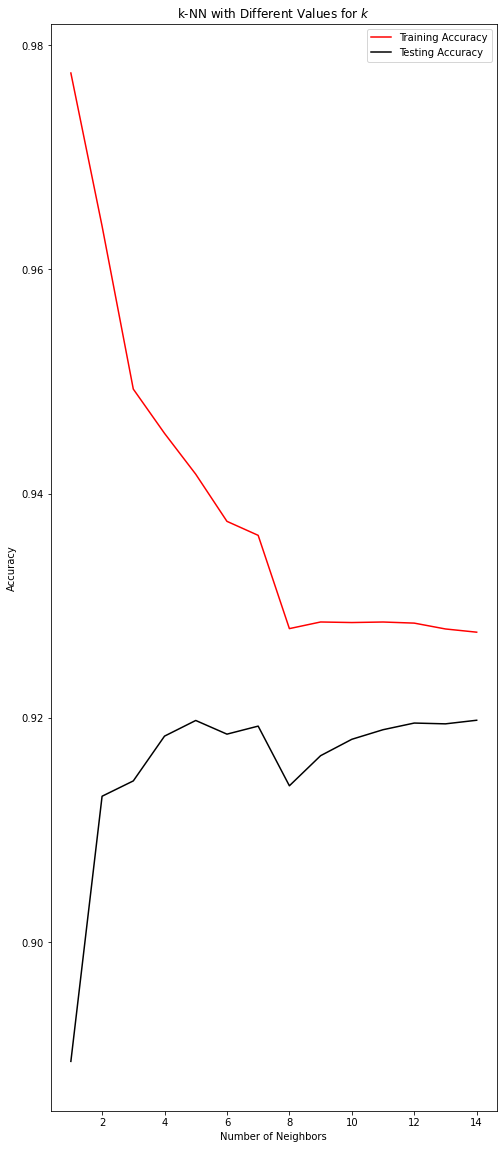

In [235]:

# Create features and target
X = df_studies.select_dtypes(exclude=['object']).drop('energy_100g', axis=1)
y = df_studies.energy_100g

# Train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8)

plot_complexity_curve(neighbors, KNeighborsRegressor, X_train, 
                      X_test, y_train, y_test)

In [236]:
nutri_app_new_seuil

,product_name,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,pnns_groups_1,pnns_groups_2,categories,categories_tags,categories_fr,image_url,nutrition-score-fr_100g,nutrition_grade_fr
0,Farine de blé noir,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Banana Chips Sweetened (Whole),2243.0,28.57,28.57,0.0,0.018,64.29,14.29,3.6,3.57,0.00000,0.000,0.0,0.0214,0.000,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,14.0,d
2,Peanuts,1941.0,17.86,0.00,0.0,0.000,60.71,17.86,7.1,17.86,0.63500,0.250,0.0,0.0000,0.071,0.00129,NaN,NaN,NaN,NaN,NaN,NaN,0.0,b
3,Organic Salted Nut Mix,2540.0,57.14,5.36,NaN,NaN,17.86,3.57,7.1,17.86,1.22428,0.482,NaN,NaN,0.143,0.00514,NaN,NaN,NaN,NaN,NaN,NaN,12.0,d
4,Organic Polenta,1552.0,1.43,NaN,NaN,NaN,77.14,NaN,5.7,8.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320767,Tomato & ricotta,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320768,"Mint Melange Tea A Blend Of Peppermint, Lemon ...",0.0,0.00,0.00,0.0,0.000,0.00,0.00,0.0,0.00,0.00000,0.000,0.0,0.0000,0.000,0.00000,NaN,NaN,NaN,NaN,NaN,NaN,0.0,b
320769,乐吧泡菜味薯片,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Salty snacks,Appetizers,Potato chips,"en:salty-snacks,en:appetizers,en:chips-and-fri...","Snacks salés,Apéritif,Chips et frites,Chips,Ch...",http://fr.openfoodfacts.org/images/products/99...,NaN,NaN
320770,Tomates aux Vermicelles,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [237]:
nutri_app_new_seuil.to_csv("/Users/laureagrech/Desktop/Alternance_Openclassrooms/projet3/studies.csv")



In [238]:
nutri_app_new_seuil.columns.to_list()

['product_name',
 'energy_100g',
 'fat_100g',
 'saturated-fat_100g',
 'trans-fat_100g',
 'cholesterol_100g',
 'carbohydrates_100g',
 'sugars_100g',
 'fiber_100g',
 'proteins_100g',
 'salt_100g',
 'sodium_100g',
 'vitamin-a_100g',
 'vitamin-c_100g',
 'calcium_100g',
 'iron_100g',
 'pnns_groups_1',
 'pnns_groups_2',
 'categories',
 'categories_tags',
 'categories_fr',
 'image_url',
 'nutrition-score-fr_100g',
 'nutrition_grade_fr']

# KNN IMPUTER

In [239]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer

In [240]:
pd.set_option('display.width',800)
pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',800)

In [241]:
df_knn_imputer = pd.read_csv("/Users/laureagrech/Desktop/Alternance_Openclassrooms/projet3/studies.csv")

In [242]:
df_knn_imputer_studies  = df_knn_imputer.dropna(subset=['nutrition-score-fr_100g','product_name'])

In [243]:
df_knn_imputer_studies.columns

Index(['Unnamed: 0', 'product_name', 'energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'calcium_100g', 'iron_100g', 'pnns_groups_1', 'pnns_groups_2', 'categories', 'categories_tags', 'categories_fr', 'image_url', 'nutrition-score-fr_100g', 'nutrition_grade_fr'], dtype='object')

In [244]:
df_knn_imputer_studies.drop(columns = ['Unnamed: 0','categories', 'categories_tags', 'categories_fr', 'image_url',
       ], axis = 1, inplace= True)

/Users/laureagrech/opt/anaconda3/lib/python3.9/site-packages/pandas/core/frame.py:4906: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return super().drop(


In [245]:
df_knn_imputer_studies

,product_name,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,pnns_groups_1,pnns_groups_2,nutrition-score-fr_100g,nutrition_grade_fr
1,Banana Chips Sweetened (Whole),2243.0,28.57,28.57,0.0,0.018,64.29,14.29,3.6,3.57,0.00000,0.000000,0.0,0.0214,0.000,0.00129,NaN,NaN,14.0,d
2,Peanuts,1941.0,17.86,0.00,0.0,0.000,60.71,17.86,7.1,17.86,0.63500,0.250000,0.0,0.0000,0.071,0.00129,NaN,NaN,0.0,b
3,Organic Salted Nut Mix,2540.0,57.14,5.36,NaN,NaN,17.86,3.57,7.1,17.86,1.22428,0.482000,NaN,NaN,0.143,0.00514,NaN,NaN,12.0,d
7,Organic Muesli,1833.0,18.75,4.69,NaN,NaN,57.81,15.62,9.4,14.06,0.13970,0.055000,NaN,NaN,0.062,0.00422,NaN,NaN,7.0,c
12,Zen Party Mix,2230.0,36.67,5.00,NaN,NaN,36.67,3.33,6.7,16.67,1.60782,0.633000,NaN,NaN,0.133,0.00360,NaN,NaN,12.0,d
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320742,Natural Cassava,1477.0,0.00,0.00,0.0,0.000,87.06,2.35,4.7,1.18,0.03048,0.012000,0.0,0.0000,0.000,0.00127,NaN,NaN,-1.0,a
320751,Tartines craquantes bio au sarrasin,1643.0,2.80,0.60,NaN,NaN,74.80,2.60,5.9,13.00,0.68000,0.267717,NaN,NaN,NaN,0.00380,Cereals and potatoes,Bread,-4.0,a
320757,Amandes,2406.0,NaN,3.73,NaN,NaN,NaN,3.89,12.2,21.22,0.10000,0.039370,NaN,NaN,NaN,NaN,NaN,NaN,0.0,b
320763,Thé vert Earl grey,21.0,0.20,0.20,NaN,NaN,0.50,0.50,0.2,0.50,0.02540,0.010000,NaN,NaN,NaN,NaN,Beverages,Non-sugared beverages,2.0,c


In [246]:
df_knn_imputer_studies = df_knn_imputer_studies.sample(n=10000).reset_index()  

# 1.Dataset studies

In [247]:
df_knn_imputer_studies

,index,product_name,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,pnns_groups_1,pnns_groups_2,nutrition-score-fr_100g,nutrition_grade_fr
0,191212,Extra Fondant,2309.0,33.00,19.00,NaN,NaN,50.00,50.00,NaN,4.90,0.08000,0.031496,NaN,NaN,NaN,NaN,Sugary snacks,Chocolate products,26.0,e
1,85579,"Pride, Bartlett Pears In Heavy Syrup",322.0,0.00,0.00,0.00,0.000,19.23,14.62,1.50,0.00,0.02032,0.008000,0.000000,0.0000,0.000,0.00000,NaN,NaN,1.0,b
2,135879,Jellied Cranberry Sauce,657.0,0.00,0.00,0.00,0.000,35.71,30.00,1.40,0.00,0.03556,0.014000,0.000000,0.0000,0.000,0.00000,NaN,NaN,6.0,c
3,126948,"Brooks Street Bakery, Classic European Pastry ...",1109.0,20.59,8.82,0.00,0.029,17.65,11.76,0.00,5.88,0.56134,0.221000,0.000353,0.0000,0.000,0.00000,NaN,NaN,15.0,d
4,196861,Sachets de 45 méga oeufs au chocolat au lait p...,2192.0,32.00,20.00,NaN,NaN,52.00,51.00,0.00,6.40,0.27000,0.106299,NaN,NaN,NaN,NaN,unknown,unknown,27.0,e
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,245254,Lait fermenté à boire LB6 nature sucré,288.0,1.40,0.90,NaN,NaN,11.20,11.20,NaN,2.70,0.10000,0.039370,NaN,NaN,0.120,NaN,unknown,unknown,1.0,b
9996,107407,Biscuits,1322.0,14.04,3.51,3.51,0.000,43.86,8.77,1.80,5.26,2.04978,0.807000,0.000000,0.0000,0.000,0.00253,NaN,NaN,13.0,d
9997,222233,Jeunes pousses d'épinard,85.0,0.70,0.14,NaN,NaN,0.10,0.05,1.58,2.80,0.14500,0.057087,NaN,NaN,NaN,NaN,Fruits and vegetables,Vegetables,-8.0,a
9998,36846,All Natural Yogurt,272.0,2.94,1.76,0.00,0.012,7.06,5.29,0.60,2.94,0.37338,0.147000,0.000035,0.0035,0.088,0.00021,NaN,NaN,2.0,b


In [248]:
df_knn_imputer_studies.isna().sum()

index                         0
product_name                  0
energy_100g                  26
fat_100g                    818
saturated-fat_100g            7
trans-fat_100g             3880
cholesterol_100g           3806
carbohydrates_100g          821
sugars_100g                   7
fiber_100g                 1204
proteins_100g                 7
salt_100g                     6
sodium_100g                   6
vitamin-a_100g             4032
vitamin-c_100g             4003
calcium_100g               3871
iron_100g                  3900
pnns_groups_1              7114
pnns_groups_2              7109
nutrition-score-fr_100g       0
nutrition_grade_fr            0
dtype: int64

# 2.OnehotEncoding

In [249]:
ohe = OneHotEncoder()

In [250]:
feature_array = ohe.fit_transform(df_knn_imputer_studies[['pnns_groups_1', 'pnns_groups_2',]]).toarray()

In [251]:
feature_array

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.]])

In [252]:
features_labels = ohe.categories_

In [253]:
features_labels

[array(['Beverages', 'Cereals and potatoes', 'Composite foods',
        'Fat and sauces', 'Fish Meat Eggs', 'Fruits and vegetables',
        'Milk and dairy products', 'Salty snacks', 'Sugary snacks',
        'cereals-and-potatoes', 'fruits-and-vegetables', 'sugary-snacks',
        'unknown', nan], dtype=object),
 array(['Alcoholic beverages', 'Appetizers',
        'Artificially sweetened beverages', 'Biscuits and cakes', 'Bread',
        'Breakfast cereals', 'Cereals', 'Cheese', 'Chocolate products',
        'Dairy desserts', 'Dressings and sauces', 'Dried fruits', 'Eggs',
        'Fats', 'Fish and seafood', 'Fruit juices', 'Fruit nectars',
        'Fruits', 'Ice cream', 'Legumes', 'Meat', 'Milk and yogurt',
        'Non-sugared beverages', 'Nuts', 'One-dish meals',
        'Pizza pies and quiche', 'Potatoes', 'Processed meat', 'Sandwich',
        'Soups', 'Sweetened beverages', 'Sweets', 'Vegetables', 'cereals',
        'fruits', 'legumes', 'pastries', 'unknown', 'vegetables', nan],


## 2.1 array : traitement des colonnes catégorielles dans un "array"

In [254]:
feature_labels = np.hstack([i.ravel() for i in features_labels])

In [255]:
feature_labels

array(['Beverages', 'Cereals and potatoes', 'Composite foods',
       'Fat and sauces', 'Fish Meat Eggs', 'Fruits and vegetables',
       'Milk and dairy products', 'Salty snacks', 'Sugary snacks',
       'cereals-and-potatoes', 'fruits-and-vegetables', 'sugary-snacks',
       'unknown', nan, 'Alcoholic beverages', 'Appetizers',
       'Artificially sweetened beverages', 'Biscuits and cakes', 'Bread',
       'Breakfast cereals', 'Cereals', 'Cheese', 'Chocolate products',
       'Dairy desserts', 'Dressings and sauces', 'Dried fruits', 'Eggs',
       'Fats', 'Fish and seafood', 'Fruit juices', 'Fruit nectars',
       'Fruits', 'Ice cream', 'Legumes', 'Meat', 'Milk and yogurt',
       'Non-sugared beverages', 'Nuts', 'One-dish meals',
       'Pizza pies and quiche', 'Potatoes', 'Processed meat', 'Sandwich',
       'Soups', 'Sweetened beverages', 'Sweets', 'Vegetables', 'cereals',
       'fruits', 'legumes', 'pastries', 'unknown', 'vegetables', nan],
      dtype=object)

In [256]:
features = pd.DataFrame(feature_array, columns = feature_labels)

In [257]:
features.columns

Index([                       'Beverages',             'Cereals and potatoes',                  'Composite foods',                   'Fat and sauces',                   'Fish Meat Eggs',            'Fruits and vegetables',          'Milk and dairy products',                     'Salty snacks',                    'Sugary snacks',             'cereals-and-potatoes',            'fruits-and-vegetables',                    'sugary-snacks',                          'unknown',                                nan,              'Alcoholic beverages',                       'Appetizers', 'Artificially sweetened beverages',               'Biscuits and cakes',                            'Bread',                'Breakfast cereals',                          'Cereals',                           'Cheese',
                     'Chocolate products',                   'Dairy desserts',             'Dressings and sauces',                     'Dried fruits',                             'Eggs',               

In [258]:
df_knn_imputer_studies = pd.concat([df_knn_imputer_studies, features], axis=1)

In [259]:
df_knn_imputer_studies

,index,product_name,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,pnns_groups_1,pnns_groups_2,nutrition-score-fr_100g,nutrition_grade_fr,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish Meat Eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,cereals-and-potatoes,fruits-and-vegetables,sugary-snacks,unknown,NaN,Alcoholic beverages,Appetizers,Artificially sweetened beverages,Biscuits and cakes,Bread,Breakfast cereals,Cereals,Cheese,Chocolate products,Dairy desserts,Dressings and sauces,Dried fruits,Eggs,Fats,Fish and seafood,Fruit juices,Fruit nectars,Fruits,Ice cream,Legumes,Meat,Milk and yogurt,Non-sugared beverages,Nuts,One-dish meals,Pizza pies and quiche,Potatoes,Processed meat,Sandwich,Soups,Sweetened beverages,Sweets,Vegetables,cereals,fruits,legumes,pastries,unknown,vegetables,NaN
0,191212,Extra Fondant,2309.0,33.00,19.00,NaN,NaN,50.00,50.00,NaN,4.90,0.08000,0.031496,NaN,NaN,NaN,NaN,Sugary snacks,Chocolate products,26.0,e,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,85579,"Pride, Bartlett Pears In Heavy Syrup",322.0,0.00,0.00,0.00,0.000,19.23,14.62,1.50,0.00,0.02032,0.008000,0.000000,0.0000,0.000,0.00000,NaN,NaN,1.0,b,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,135879,Jellied Cranberry Sauce,657.0,0.00,0.00,0.00,0.000,35.71,30.00,1.40,0.00,0.03556,0.014000,0.000000,0.0000,0.000,0.00000,NaN,NaN,6.0,c,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,126948,"Brooks Street Bakery, Classic European Pastry ...",1109.0,20.59,8.82,0.00,0.029,17.65,11.76,0.00,5.88,0.56134,0.221000,0.000353,0.0000,0.000,0.00000,NaN,NaN,15.0,d,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,196861,Sachets de 45 méga oeufs au chocolat au lait p...,2192.0,32.00,20.00,NaN,NaN,52.00,51.00,0.00,6.40,0.27000,0.106299,NaN,NaN,NaN,NaN,unknown,unknown,27.0,e,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,245254,Lait fermenté à boire LB6 nature sucré,288.0,1.40,0.90,NaN,NaN,11.20,11.20,NaN,2.70,0.10000,0.039370,NaN,NaN,0.120,NaN,unknown,unknown,1.0,b,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
9996,107407,Biscuits,1322.0,14.04,3.51,3.51,0.000,43.86,8.77,1.80,5.26,2.04978,0.807000,0.000000,0.0000,0.000,0.00253,NaN,NaN,13.0,d,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
9997,222233,Jeunes pousses d'épinard,85.0,0.70,0.14,NaN,NaN,0.10,0.05,1.58,2.80,0.14500,0.057087,NaN,NaN,NaN,NaN,Frui

## 2.2 traitement des NaNs

In [260]:
nan_col = df_knn_imputer_studies.copy()

In [261]:
col_mapping_dict = {c[0]:c[1] for c in enumerate(df_knn_imputer_studies.columns)}
col_mapping_dict 

{0: 'index',
 1: 'product_name',
 2: 'energy_100g',
 3: 'fat_100g',
 4: 'saturated-fat_100g',
 5: 'trans-fat_100g',
 6: 'cholesterol_100g',
 7: 'carbohydrates_100g',
 8: 'sugars_100g',
 9: 'fiber_100g',
 10: 'proteins_100g',
 11: 'salt_100g',
 12: 'sodium_100g',
 13: 'vitamin-a_100g',
 14: 'vitamin-c_100g',
 15: 'calcium_100g',
 16: 'iron_100g',
 17: 'pnns_groups_1',
 18: 'pnns_groups_2',
 19: 'nutrition-score-fr_100g',
 20: 'nutrition_grade_fr',
 21: 'Beverages',
 22: 'Cereals and potatoes',
 23: 'Composite foods',
 24: 'Fat and sauces',
 25: 'Fish Meat Eggs',
 26: 'Fruits and vegetables',
 27: 'Milk and dairy products',
 28: 'Salty snacks',
 29: 'Sugary snacks',
 30: 'cereals-and-potatoes',
 31: 'fruits-and-vegetables',
 32: 'sugary-snacks',
 33: 'unknown',
 34: nan,
 35: 'Alcoholic beverages',
 36: 'Appetizers',
 37: 'Artificially sweetened beverages',
 38: 'Biscuits and cakes',
 39: 'Bread',
 40: 'Breakfast cereals',
 41: 'Cereals',
 42: 'Cheese',
 43: 'Chocolate products',
 44: 'D

In [262]:
nan_col.columns.values[34] = "new_lbl0"
nan_col.columns.values[74] = "new_lbl"

In [263]:
col_mapping_dict = {c[0]:c[1] for c in enumerate(nan_col.columns)}
col_mapping_dict 

{0: 'index',
 1: 'product_name',
 2: 'energy_100g',
 3: 'fat_100g',
 4: 'saturated-fat_100g',
 5: 'trans-fat_100g',
 6: 'cholesterol_100g',
 7: 'carbohydrates_100g',
 8: 'sugars_100g',
 9: 'fiber_100g',
 10: 'proteins_100g',
 11: 'salt_100g',
 12: 'sodium_100g',
 13: 'vitamin-a_100g',
 14: 'vitamin-c_100g',
 15: 'calcium_100g',
 16: 'iron_100g',
 17: 'pnns_groups_1',
 18: 'pnns_groups_2',
 19: 'nutrition-score-fr_100g',
 20: 'nutrition_grade_fr',
 21: 'Beverages',
 22: 'Cereals and potatoes',
 23: 'Composite foods',
 24: 'Fat and sauces',
 25: 'Fish Meat Eggs',
 26: 'Fruits and vegetables',
 27: 'Milk and dairy products',
 28: 'Salty snacks',
 29: 'Sugary snacks',
 30: 'cereals-and-potatoes',
 31: 'fruits-and-vegetables',
 32: 'sugary-snacks',
 33: 'unknown',
 34: 'new_lbl0',
 35: 'Alcoholic beverages',
 36: 'Appetizers',
 37: 'Artificially sweetened beverages',
 38: 'Biscuits and cakes',
 39: 'Bread',
 40: 'Breakfast cereals',
 41: 'Cereals',
 42: 'Cheese',
 43: 'Chocolate products',


In [264]:
col_mapping_dict.values()

dict_values(['index', 'product_name', 'energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'calcium_100g', 'iron_100g', 'pnns_groups_1', 'pnns_groups_2', 'nutrition-score-fr_100g', 'nutrition_grade_fr', 'Beverages', 'Cereals and potatoes', 'Composite foods', 'Fat and sauces', 'Fish Meat Eggs', 'Fruits and vegetables', 'Milk and dairy products', 'Salty snacks', 'Sugary snacks', 'cereals-and-potatoes', 'fruits-and-vegetables', 'sugary-snacks', 'unknown', 'new_lbl0', 'Alcoholic beverages', 'Appetizers', 'Artificially sweetened beverages', 'Biscuits and cakes', 'Bread', 'Breakfast cereals', 'Cereals', 'Cheese', 'Chocolate products', 'Dairy desserts', 'Dressings and sauces', 'Dried fruits', 'Eggs', 'Fats', 'Fish and seafood', 'Fruit juices', 'Fruit nectars', 'Fruits', 'Ice cream', 'Legumes', 'Meat', 'Milk and yogurt', 'Non-suga

In [268]:
cat1 = ['Beverages', 'Cereals and potatoes', 'Composite foods', 'Fat and sauces', 'Fish Meat Eggs', 'Fruits and vegetables', 'Milk and dairy products', 'Salty snacks', 'Sugary snacks', 'cereals-and-potatoes', 'fruits-and-vegetables', 'sugary-snacks', 'unknown']
cat2 = ['Alcoholic beverages', 'Appetizers', 'Artificially sweetened beverages', 'Biscuits and cakes', 'Bread', 'Breakfast cereals', 'Cereals', 'Cheese', 'Chocolate products', 'Dairy desserts', 'Dressings and sauces', 'Dried fruits', 'Eggs', 'Fats', 'Fish and seafood', 'Fruit juices', 'Fruit nectars', 'Fruits', 'Ice cream', 'Legumes', 'Meat', 'Milk and yogurt', 'Non-sugared beverages', 'Nuts', 'One-dish meals', 'Pizza pies and quiche', 'Potatoes', 'Processed meat', 'Sandwich', 'Soups', 'Sweetened beverages', 'Sweets', 'Vegetables', 'cereals', 'fruits', 'legumes', 'pastries', 'unknown', 'vegetables']



In [269]:
nan_col.drop(columns='index', inplace =True)

KeyError: "['index'] not found in axis"

## 2.3 pour les 2 colonnes à nan mettre toutes les 2 cat onehotencodée à nan

In [270]:
nan_col.loc[nan_col['new_lbl0'] == 1 , cat1] = np.NaN

In [271]:
nan_col.head(2)

,product_name,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,pnns_groups_1,pnns_groups_2,nutrition-score-fr_100g,nutrition_grade_fr,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish Meat Eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,cereals-and-potatoes,fruits-and-vegetables,sugary-snacks,unknown,new_lbl0,Alcoholic beverages,Appetizers,Artificially sweetened beverages,Biscuits and cakes,Bread,Breakfast cereals,Cereals,Cheese,Chocolate products,Dairy desserts,Dressings and sauces,Dried fruits,Eggs,Fats,Fish and seafood,Fruit juices,Fruit nectars,Fruits,Ice cream,Legumes,Meat,Milk and yogurt,Non-sugared beverages,Nuts,One-dish meals,Pizza pies and quiche,Potatoes,Processed meat,Sandwich,Soups,Sweetened beverages,Sweets,Vegetables,cereals,fruits,legumes,pastries,unknown,vegetables,new_lbl
0,Extra Fondant,2309.0,33.0,19.0,NaN,NaN,50.00,50.00,NaN,4.9,0.08000,0.031496,NaN,NaN,NaN,NaN,Sugary snacks,Chocolate products,26.0,e,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,"Pride, Bartlett Pears In Heavy Syrup",322.0,0.0,0.0,0.0,0.0,19.23,14.62,1.5,0.0,0.02032,0.008000,0.0,0.0,0.0,0.0,NaN,NaN,1.0,b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,1.0


In [272]:
nan_col.loc[nan_col['new_lbl'] == 1 , cat2] = np.NaN

In [273]:
nan_col.head(2)

,product_name,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,pnns_groups_1,pnns_groups_2,nutrition-score-fr_100g,nutrition_grade_fr,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish Meat Eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,cereals-and-potatoes,fruits-and-vegetables,sugary-snacks,unknown,new_lbl0,Alcoholic beverages,Appetizers,Artificially sweetened beverages,Biscuits and cakes,Bread,Breakfast cereals,Cereals,Cheese,Chocolate products,Dairy desserts,Dressings and sauces,Dried fruits,Eggs,Fats,Fish and seafood,Fruit juices,Fruit nectars,Fruits,Ice cream,Legumes,Meat,Milk and yogurt,Non-sugared beverages,Nuts,One-dish meals,Pizza pies and quiche,Potatoes,Processed meat,Sandwich,Soups,Sweetened beverages,Sweets,Vegetables,cereals,fruits,legumes,pastries,unknown,vegetables,new_lbl
0,Extra Fondant,2309.0,33.0,19.0,NaN,NaN,50.00,50.00,NaN,4.9,0.08000,0.031496,NaN,NaN,NaN,NaN,Sugary snacks,Chocolate products,26.0,e,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,"Pride, Bartlett Pears In Heavy Syrup",322.0,0.0,0.0,0.0,0.0,19.23,14.62,1.5,0.0,0.02032,0.008000,0.0,0.0,0.0,0.0,NaN,NaN,1.0,b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


In [274]:
nan_col.rename(columns={'new_lbl0':np.nan,'new_lbl':np.nan}, inplace=True)
nan_col.head(2)

,product_name,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,pnns_groups_1,pnns_groups_2,nutrition-score-fr_100g,nutrition_grade_fr,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish Meat Eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,cereals-and-potatoes,fruits-and-vegetables,sugary-snacks,unknown,NaN,Alcoholic beverages,Appetizers,Artificially sweetened beverages,Biscuits and cakes,Bread,Breakfast cereals,Cereals,Cheese,Chocolate products,Dairy desserts,Dressings and sauces,Dried fruits,Eggs,Fats,Fish and seafood,Fruit juices,Fruit nectars,Fruits,Ice cream,Legumes,Meat,Milk and yogurt,Non-sugared beverages,Nuts,One-dish meals,Pizza pies and quiche,Potatoes,Processed meat,Sandwich,Soups,Sweetened beverages,Sweets,Vegetables,cereals,fruits,legumes,pastries,unknown,vegetables,NaN
0,Extra Fondant,2309.0,33.0,19.0,NaN,NaN,50.00,50.00,NaN,4.9,0.08000,0.031496,NaN,NaN,NaN,NaN,Sugary snacks,Chocolate products,26.0,e,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,"Pride, Bartlett Pears In Heavy Syrup",322.0,0.0,0.0,0.0,0.0,19.23,14.62,1.5,0.0,0.02032,0.008000,0.0,0.0,0.0,0.0,NaN,NaN,1.0,b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


In [275]:
nan_col.columns

Index([                    'product_name',                      'energy_100g',                         'fat_100g',               'saturated-fat_100g',                   'trans-fat_100g',                 'cholesterol_100g',               'carbohydrates_100g',                      'sugars_100g',                       'fiber_100g',                    'proteins_100g',                        'salt_100g',                      'sodium_100g',                   'vitamin-a_100g',                   'vitamin-c_100g',                     'calcium_100g',                        'iron_100g',                    'pnns_groups_1',                    'pnns_groups_2',          'nutrition-score-fr_100g',               'nutrition_grade_fr',                        'Beverages',             'Cereals and potatoes',
                        'Composite foods',                   'Fat and sauces',                   'Fish Meat Eggs',            'Fruits and vegetables',          'Milk and dairy products',               

In [276]:
nan_col.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 74 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   product_name                      10000 non-null  object 
 1   energy_100g                       9974 non-null   float64
 2   fat_100g                          9182 non-null   float64
 3   saturated-fat_100g                9993 non-null   float64
 4   trans-fat_100g                    6120 non-null   float64
 5   cholesterol_100g                  6194 non-null   float64
 6   carbohydrates_100g                9179 non-null   float64
 7   sugars_100g                       9993 non-null   float64
 8   fiber_100g                        8796 non-null   float64
 9   proteins_100g                     9993 non-null   float64
 10  salt_100g                         9994 non-null   float64
 11  sodium_100g                       9994 non-null   float64
 12  vitam

In [277]:
knn_imputer_df_col = nan_col.select_dtypes(exclude=['object']) 
knn_imputer_df_col.head(2)

,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish Meat Eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,cereals-and-potatoes,fruits-and-vegetables,sugary-snacks,unknown,NaN,Alcoholic beverages,Appetizers,Artificially sweetened beverages,Biscuits and cakes,Bread,Breakfast cereals,Cereals,Cheese,Chocolate products,Dairy desserts,Dressings and sauces,Dried fruits,Eggs,Fats,Fish and seafood,Fruit juices,Fruit nectars,Fruits,Ice cream,Legumes,Meat,Milk and yogurt,Non-sugared beverages,Nuts,One-dish meals,Pizza pies and quiche,Potatoes,Processed meat,Sandwich,Soups,Sweetened beverages,Sweets,Vegetables,cereals,fruits,legumes,pastries,unknown,vegetables,NaN
0,2309.0,33.0,19.0,NaN,NaN,50.00,50.00,NaN,4.9,0.08000,0.031496,NaN,NaN,NaN,NaN,26.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,322.0,0.0,0.0,0.0,0.0,19.23,14.62,1.5,0.0,0.02032,0.008000,0.0,0.0,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


In [278]:
knn_imputer_df_col.head(2).info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 70 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   energy_100g                       2 non-null      float64
 1   fat_100g                          2 non-null      float64
 2   saturated-fat_100g                2 non-null      float64
 3   trans-fat_100g                    1 non-null      float64
 4   cholesterol_100g                  1 non-null      float64
 5   carbohydrates_100g                2 non-null      float64
 6   sugars_100g                       2 non-null      float64
 7   fiber_100g                        1 non-null      float64
 8   proteins_100g                     2 non-null      float64
 9   salt_100g                         2 non-null      float64
 10  sodium_100g                       2 non-null      float64
 11  vitamin-a_100g                    1 non-null      float64
 12  vitamin-c_10

# 3. minMax scaler

In [279]:
from sklearn.preprocessing import MinMaxScaler

In [280]:
knn_imputer_df_col.columns

Index([                     'energy_100g',                         'fat_100g',               'saturated-fat_100g',                   'trans-fat_100g',                 'cholesterol_100g',               'carbohydrates_100g',                      'sugars_100g',                       'fiber_100g',                    'proteins_100g',                        'salt_100g',                      'sodium_100g',                   'vitamin-a_100g',                   'vitamin-c_100g',                     'calcium_100g',                        'iron_100g',          'nutrition-score-fr_100g',                        'Beverages',             'Cereals and potatoes',                  'Composite foods',                   'Fat and sauces',                   'Fish Meat Eggs',            'Fruits and vegetables',
                'Milk and dairy products',                     'Salty snacks',                    'Sugary snacks',             'cereals-and-potatoes',            'fruits-and-vegetables',               

In [281]:
scaler = MinMaxScaler()
knn_imputer_df_col = pd.DataFrame(scaler.fit_transform(knn_imputer_df_col), columns = knn_imputer_df_col.columns)
knn_imputer_df_col.head()

,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish Meat Eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,cereals-and-potatoes,fruits-and-vegetables,sugary-snacks,unknown,NaN,Alcoholic beverages,Appetizers,Artificially sweetened beverages,Biscuits and cakes,Bread,Breakfast cereals,Cereals,Cheese,Chocolate products,Dairy desserts,Dressings and sauces,Dried fruits,Eggs,Fats,Fish and seafood,Fruit juices,Fruit nectars,Fruits,Ice cream,Legumes,Meat,Milk and yogurt,Non-sugared beverages,Nuts,One-dish meals,Pizza pies and quiche,Potatoes,Processed meat,Sandwich,Soups,Sweetened beverages,Sweets,Vegetables,cereals,fruits,legumes,pastries,unknown,vegetables,NaN
0,0.613932,0.3300,0.206522,NaN,NaN,0.5000,0.5000,NaN,0.070000,0.000800,0.000800,NaN,NaN,NaN,NaN,0.735849,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.085616,0.0000,0.000000,0.0,0.000000,0.1923,0.1462,0.015,0.000000,0.000203,0.000203,0.00000,0.0,0.0,0.0,0.264151,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
2,0.174688,0.0000,0.000000,0.0,0.000000,0.3571,0.3000,0.014,0.000000,0.000356,0.000356,0.00000,0.0,0.0,0.0,0.358491,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
3,0.294868,0.2059,0.095870,0.0,0.002661,0.1765,0.1176,0.000,0.084000,0.005613,0.005613,0.02352,0.0,0.0,0.0,0.528302,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
4,0.582824,0.3200,0.217391,NaN,NaN,0.5200,0.5100,0.000,0.091429,0.002700,0.002700,NaN,NaN,NaN,NaN,0.754717,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


# 4. Knn imputer = 1

In [282]:
df_knn_imputer = knn_imputer_df_col

In [283]:
from sklearn.impute import KNNImputer

In [284]:
knn = KNNImputer(n_neighbors=1, add_indicator=False)

In [285]:
df_knn_imputer = pd.DataFrame(knn.fit_transform(df_knn_imputer),columns = df_knn_imputer.columns)

In [286]:
df_knn_imputer

,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish Meat Eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,cereals-and-potatoes,fruits-and-vegetables,sugary-snacks,unknown,NaN,Alcoholic beverages,Appetizers,Artificially sweetened beverages,Biscuits and cakes,Bread,Breakfast cereals,Cereals,Cheese,Chocolate products,Dairy desserts,Dressings and sauces,Dried fruits,Eggs,Fats,Fish and seafood,Fruit juices,Fruit nectars,Fruits,Ice cream,Legumes,Meat,Milk and yogurt,Non-sugared beverages,Nuts,One-dish meals,Pizza pies and quiche,Potatoes,Processed meat,Sandwich,Soups,Sweetened beverages,Sweets,Vegetables,cereals,fruits,legumes,pastries,unknown,vegetables,NaN
0,0.613932,0.3300,0.206522,0.000000,1.000000,0.5000,0.5000,0.0210,0.070000,0.000800,0.000800,0.005000,0.000000,0.014166,0.000964,0.735849,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.085616,0.0000,0.000000,0.000000,0.000000,0.1923,0.1462,0.0150,0.000000,0.000203,0.000203,0.000000,0.000000,0.000000,0.000000,0.264151,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,0.174688,0.0000,0.000000,0.000000,0.000000,0.3571,0.3000,0.0140,0.000000,0.000356,0.000356,0.000000,0.000000,0.000000,0.000000,0.358491,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.294868,0.2059,0.095870,0.000000,0.002661,0.1765,0.1176,0.0000,0.084000,0.005613,0.005613,0.023520,0.000000,0.000000,0.000000,0.528302,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.582824,0.3200,0.217391,0.000000,0.000000,0.5200,0.5100,0.0000,0.091429,0.002700,0.002700,0.035133,0.043683,0.017443,0.001857,0.754717,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0.076575,0.0140,0.009783,0.001563,0.000000,0.1120,0.1120,0.0130,0.038571,0.001000,0.001000,0.006733,0.009610,0.006343,0.000750,0.264151,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
9996,0.351502,0.1404,0.038152,0.054844,0.000000,0.4386,0.0877,0.0180,0.075143,0.020498,0.020498,0.000000,0.000000,0.000000,0.000904,0.490566,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
9997,0.022600,0.0070,0.001522,0.000000,0.000000,0.0010,0.0005,0.0158,0.040000,0.001450,0.001450,0.000000,0.000000,0.000920,0.000224,0.094340,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.

## 5 dehencode

In [287]:
df_cat_studies = df_knn_imputer.copy()

In [288]:
df_cat_studies_cat = df_cat_studies.loc[:, df_cat_studies.columns.isin(feature_labels)]

In [289]:
imputed_cat = ohe.inverse_transform(df_cat_studies_cat)
imputed_cat.shape

(10000, 2)

In [290]:
df_imputed_cat = pd.DataFrame(imputed_cat, columns=['pnns_group1', 'pnns_group2'])
df_imputed_cat

,pnns_group1,pnns_group2
0,Sugary snacks,Chocolate products
1,unknown,Alcoholic beverages
2,Fat and sauces,Alcoholic beverages
3,Fat and sauces,Alcoholic beverages
4,unknown,unknown
...,...,...
9995,unknown,unknown
9996,unknown,Alcoholic beverages
9997,Fruits and vegetables,Vegetables
9998,Milk and dairy products,Alcoholic beverages


# reverse min max scaler for numerical data

In [291]:
final_df_nutri_app_studies = pd.DataFrame(scaler.inverse_transform(df_knn_imputer), columns = df_knn_imputer.columns)
final_df_nutri_app_studies.head()

,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish Meat Eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,cereals-and-potatoes,fruits-and-vegetables,sugary-snacks,unknown,NaN,Alcoholic beverages,Appetizers,Artificially sweetened beverages,Biscuits and cakes,Bread,Breakfast cereals,Cereals,Cheese,Chocolate products,Dairy desserts,Dressings and sauces,Dried fruits,Eggs,Fats,Fish and seafood,Fruit juices,Fruit nectars,Fruits,Ice cream,Legumes,Meat,Milk and yogurt,Non-sugared beverages,Nuts,One-dish meals,Pizza pies and quiche,Potatoes,Processed meat,Sandwich,Soups,Sweetened beverages,Sweets,Vegetables,cereals,fruits,legumes,pastries,unknown,vegetables,NaN
0,2309.0,33.00,19.00,0.0,10.900,50.00,50.00,2.1,4.90,0.08000,0.031496,0.000075,0.000,0.268,0.0027,26.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,322.0,0.00,0.00,0.0,0.000,19.23,14.62,1.5,0.00,0.02032,0.008000,0.000000,0.000,0.000,0.0000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,657.0,0.00,0.00,0.0,0.000,35.71,30.00,1.4,0.00,0.03556,0.014000,0.000000,0.000,0.000,0.0000,6.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1109.0,20.59,8.82,0.0,0.029,17.65,11.76,0.0,5.88,0.56134,0.221000,0.000353,0.000,0.000,0.0000,15.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2192.0,32.00,20.00,0.0,0.000,52.00,51.00,0.0,6.40,0.27000,0.106299,0.000527,0.065,0.330,0.0052,27.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [292]:
df_studies_notcat = final_df_nutri_app_studies.loc[:, ~final_df_nutri_app_studies.columns.isin(feature_labels)]
df_studies_notcat

,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g
0,2309.0,33.00,19.00,0.00,10.900,50.00,50.00,2.10,4.90,0.08000,0.031496,0.000075,0.0000,0.2680,0.002700,26.0
1,322.0,0.00,0.00,0.00,0.000,19.23,14.62,1.50,0.00,0.02032,0.008000,0.000000,0.0000,0.0000,0.000000,1.0
2,657.0,0.00,0.00,0.00,0.000,35.71,30.00,1.40,0.00,0.03556,0.014000,0.000000,0.0000,0.0000,0.000000,6.0
3,1109.0,20.59,8.82,0.00,0.029,17.65,11.76,0.00,5.88,0.56134,0.221000,0.000353,0.0000,0.0000,0.000000,15.0
4,2192.0,32.00,20.00,0.00,0.000,52.00,51.00,0.00,6.40,0.27000,0.106299,0.000527,0.0650,0.3300,0.005200,27.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,288.0,1.40,0.90,0.10,0.000,11.20,11.20,1.30,2.70,0.10000,0.039370,0.000101,0.0143,0.1200,0.002100,1.0
9996,1322.0,14.04,3.51,3.51,0.000,43.86,8.77,1.80,5.26,2.04978,0.807000,0.000000,0.0000,0.0000,0.002530,13.0
9997,85.0,0.70,0.14,0.00,0.000,0.10,0.05,1.58,2.80,0.14500,0.057087,0.000000,0.0000,0.0174,0.000626,-8.0
9998,272.0,2.94,1.76,0.00,0.012,7.06,5.29,0.60,2.94,0.37338,0.147000,0.000035,0.0035,0.0880,0.000210,2.0


In [293]:
final_df_nutri_app_studies = pd.concat([df_imputed_cat,df_studies_notcat], axis=1)
final_df_nutri_app_studies                                   

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g
0,Sugary snacks,Chocolate products,2309.0,33.00,19.00,0.00,10.900,50.00,50.00,2.10,4.90,0.08000,0.031496,0.000075,0.0000,0.2680,0.002700,26.0
1,unknown,Alcoholic beverages,322.0,0.00,0.00,0.00,0.000,19.23,14.62,1.50,0.00,0.02032,0.008000,0.000000,0.0000,0.0000,0.000000,1.0
2,Fat and sauces,Alcoholic beverages,657.0,0.00,0.00,0.00,0.000,35.71,30.00,1.40,0.00,0.03556,0.014000,0.000000,0.0000,0.0000,0.000000,6.0
3,Fat and sauces,Alcoholic beverages,1109.0,20.59,8.82,0.00,0.029,17.65,11.76,0.00,5.88,0.56134,0.221000,0.000353,0.0000,0.0000,0.000000,15.0
4,unknown,unknown,2192.0,32.00,20.00,0.00,0.000,52.00,51.00,0.00,6.40,0.27000,0.106299,0.000527,0.0650,0.3300,0.005200,27.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,unknown,unknown,288.0,1.40,0.90,0.10,0.000,11.20,11.20,1.30,2.70,0.10000,0.039370,0.000101,0.0143,0.1200,0.002100,1.0
9996,unknown,Alcoholic beverages,1322.0,14.04,3.51,3.51,0.000,43.86,8.77,1.80,5.26,2.04978,0.807000,0.000000,0.0000,0.0000,0.002530,13.0
9997,Fruits and vegetables,Vegetables,85.0,0.70,0.14,0.00,0.000,0.10,0.05,1.58,2.80,0.14500,0.057087,0.000000,0.0000,0.0174,0.000626,-8.0
9998,Milk and dairy products,Alcoholic beverages,272.0,2.94,1.76,0.00,0.012,7.06,5.29,0.60,2.94,0.37338,0.147000,0.000035,0.0035,0.0880,0.000210,2.0


In [294]:
final_df_nutri_app_studies=pd.concat([final_df_nutri_app_studies,df_knn_imputer_studies[["nutrition_grade_fr","product_name"]]], axis=1)

In [295]:
final_df_nutri_app_studies

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
0,Sugary snacks,Chocolate products,2309.0,33.00,19.00,0.00,10.900,50.00,50.00,2.10,4.90,0.08000,0.031496,0.000075,0.0000,0.2680,0.002700,26.0,e,Extra Fondant
1,unknown,Alcoholic beverages,322.0,0.00,0.00,0.00,0.000,19.23,14.62,1.50,0.00,0.02032,0.008000,0.000000,0.0000,0.0000,0.000000,1.0,b,"Pride, Bartlett Pears In Heavy Syrup"
2,Fat and sauces,Alcoholic beverages,657.0,0.00,0.00,0.00,0.000,35.71,30.00,1.40,0.00,0.03556,0.014000,0.000000,0.0000,0.0000,0.000000,6.0,c,Jellied Cranberry Sauce
3,Fat and sauces,Alcoholic beverages,1109.0,20.59,8.82,0.00,0.029,17.65,11.76,0.00,5.88,0.56134,0.221000,0.000353,0.0000,0.0000,0.000000,15.0,d,"Brooks Street Bakery, Classic European Pastry ..."
4,unknown,unknown,2192.0,32.00,20.00,0.00,0.000,52.00,51.00,0.00,6.40,0.27000,0.106299,0.000527,0.0650,0.3300,0.005200,27.0,e,Sachets de 45 méga oeufs au chocolat au lait p...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,unknown,unknown,288.0,1.40,0.90,0.10,0.000,11.20,11.20,1.30,2.70,0.10000,0.039370,0.000101,0.0143,0.1200,0.002100,1.0,b,Lait fermenté à boire LB6 nature sucré
9996,unknown,Alcoholic beverages,1322.0,14.04,3.51,3.51,0.000,43.86,8.77,1.80,5.26,2.04978,0.807000,0.000000,0.0000,0.0000,0.002530,13.0,d,Biscuits
9997,Fruits and vegetables,Vegetables,85.0,0.70,0.14,0.00,0.000,0.10,0.05,1.58,2.80,0.14500,0.057087,0.000000,0.0000,0.0174,0.000626,-8.0,a,Jeunes pousses d'épinard
9998,Milk and dairy products,Alcoholic beverages,272.0,2.94,1.76,0.00,0.012,7.06,5.29,0.60,2.94,0.37338,0.147000,0.000035,0.0035,0.0880,0.000210,2.0,b,All Natural Yogurt


In [296]:
final_df_nutri_app_studies

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
0,Sugary snacks,Chocolate products,2309.0,33.00,19.00,0.00,10.900,50.00,50.00,2.10,4.90,0.08000,0.031496,0.000075,0.0000,0.2680,0.002700,26.0,e,Extra Fondant
1,unknown,Alcoholic beverages,322.0,0.00,0.00,0.00,0.000,19.23,14.62,1.50,0.00,0.02032,0.008000,0.000000,0.0000,0.0000,0.000000,1.0,b,"Pride, Bartlett Pears In Heavy Syrup"
2,Fat and sauces,Alcoholic beverages,657.0,0.00,0.00,0.00,0.000,35.71,30.00,1.40,0.00,0.03556,0.014000,0.000000,0.0000,0.0000,0.000000,6.0,c,Jellied Cranberry Sauce
3,Fat and sauces,Alcoholic beverages,1109.0,20.59,8.82,0.00,0.029,17.65,11.76,0.00,5.88,0.56134,0.221000,0.000353,0.0000,0.0000,0.000000,15.0,d,"Brooks Street Bakery, Classic European Pastry ..."
4,unknown,unknown,2192.0,32.00,20.00,0.00,0.000,52.00,51.00,0.00,6.40,0.27000,0.106299,0.000527,0.0650,0.3300,0.005200,27.0,e,Sachets de 45 méga oeufs au chocolat au lait p...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,unknown,unknown,288.0,1.40,0.90,0.10,0.000,11.20,11.20,1.30,2.70,0.10000,0.039370,0.000101,0.0143,0.1200,0.002100,1.0,b,Lait fermenté à boire LB6 nature sucré
9996,unknown,Alcoholic beverages,1322.0,14.04,3.51,3.51,0.000,43.86,8.77,1.80,5.26,2.04978,0.807000,0.000000,0.0000,0.0000,0.002530,13.0,d,Biscuits
9997,Fruits and vegetables,Vegetables,85.0,0.70,0.14,0.00,0.000,0.10,0.05,1.58,2.80,0.14500,0.057087,0.000000,0.0000,0.0174,0.000626,-8.0,a,Jeunes pousses d'épinard
9998,Milk and dairy products,Alcoholic beverages,272.0,2.94,1.76,0.00,0.012,7.06,5.29,0.60,2.94,0.37338,0.147000,0.000035,0.0035,0.0880,0.000210,2.0,b,All Natural Yogurt


In [297]:
final_df_nutri_app_studies.to_csv("/Users/laureagrech/Desktop/Alternance_Openclassrooms/projet3/dataset_cleaned_pour_analyse_exploratoire.csv")